# Price Optimization - Generic Business Pricing Engine

**Role in the pipeline**

```
Raw Company Data -> Feature Engineering -> Modeling (demand forecast) -> Price Optimization (this notebook)
```

This notebook converts **demand forecasts** and **historical pricing information** into **price
scenarios** and a **revenue / profit optimization** for one product series. It is generic: no product
ID, store ID or dataset-specific value is hardcoded - every column name, threshold and business rule
lives in the configuration cell.

### The four stages are kept deliberately separate

| # | Stage | What happens here | What it is **not** |
|---|-------|-------------------|--------------------|
| 1 | **Demand prediction** | The saved forecasting model predicts demand for the current historical observation | not an estimate of what a price change would *cause* |
| 2 | **Price / elasticity estimation** | A transparent log-log regression describes the historical price-demand relationship | not a causally identified elasticity |
| 3 | **Scenario simulation** | A configurable constant-elasticity formula translates the baseline forecast into scenario demand at alternative prices | not the ML model predicting counterfactuals |
| 4 | **Profit optimization** | Scenarios are scored (revenue, or profit when the business provides unit cost) and the best one is chosen under business guardrails | not an autonomous repricing system |

> **Decision support, not autonomy.** The output is a *recommendation with stated assumptions,
> sensitivity analysis and guardrails*, intended for business review. The engine never changes a
> price by itself.

> **The demand model is predictive, not causal.** A high forecast accuracy says the model predicts
> demand well under historical conditions. It does **not** mean that changing the price will change
> demand by the model's prediction. Every price-driven number below comes from an explicitly
> labelled **elasticity assumption or observational estimate**, and every recommendation must be
> validated with a controlled experiment (A/B test) or business review before deployment.

**Artifacts consumed** (produced by `Feature_Engineering.ipynb` and `Modeling.ipynb`, never modified here):

* `Data/demand_forecasting_engineered.csv`
* `Models/demand_forecasting_model.pkl`
* `Models/model_metadata.json`


## 1. Imports

Only what the notebook needs. Display options are set here so every table further down is readable.

In [1]:
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

%matplotlib inline

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 200)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| joblib {joblib.__version__} | matplotlib {matplotlib.__version__}")


pandas 3.0.6 | numpy 2.1.3 | scikit-learn 1.6.1 | joblib 1.6.0 | matplotlib 3.11.2


## 2. Configuration

Everything that may differ between companies, datasets or products lives in this single cell:
**paths, scenario settings, elasticity assumptions, data-quality thresholds and business guardrails**.

Column **names** are configured - column **values** (product IDs, store IDs, prices of a specific SKU)
are never configured, so the notebook is reusable on any company's historical pricing data.

| Group | Key settings |
|-------|--------------|
| Scenario grid | `N_SCENARIOS`, `PRICE_LOW_QUANTILE`, `PRICE_HIGH_QUANTILE` - the search space stays inside the historical price distribution |
| Elasticity | `DEFAULT_ELASTICITY`, `ELASTICITY_MIN/MAX`, `ELASTICITY_GRID` |
| Business input | `DEFAULT_UNIT_COST = None` - a unit cost is **only** used if the business provides it |
| Guardrails | `MAX_PRICE_CHANGE_PCT`, `MIN_PROFIT_MARGIN`, `MIN_EXPECTED_DEMAND`, `MIN_PRICE`, `MAX_PRICE` |

In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================
# --- Artifacts produced by Feature_Engineering.ipynb / Modeling.ipynb --------
DATA_PATH     = "../Data/demand_forecasting_engineered.csv"
MODEL_PATH    = "../Models/demand_forecasting_model.pkl"
METADATA_PATH = "../Models/model_metadata.json"


def _join_case_insensitive(base, parts):
    '''Walk `parts` under `base`, matching each part case-insensitively (Data vs data).'''
    current = Path(base)
    for part in parts:
        candidate = current / part
        if not candidate.exists() and current.exists():
            for child in current.iterdir():
                if child.name.lower() == str(part).lower():
                    candidate = child
                    break
        current = candidate
    return current


def resolve_artifact_path(configured):
    '''Resolve a configured path whether the kernel starts in Notebooks/ or in the project root.'''
    configured = Path(configured)
    if configured.is_absolute():
        roots_and_parts = [(Path(configured.anchor), configured.parts[1:])]
    else:
        roots = [Path.cwd(), Path.cwd().parent, *Path.cwd().parents]
        roots_and_parts = [(root, configured.parts) for root in roots]

    tried = []
    for root, parts in roots_and_parts:
        resolved = _join_case_insensitive(root, parts)
        tried.append(resolved)
        if resolved.exists():
            return resolved.resolve()
    raise FileNotFoundError(
        "Required artifact not found: "
        + str(configured)
        + "\nTried:\n  "
        + "\n  ".join(str(p) for p in tried)
        + "\nRun Feature_Engineering.ipynb and Modeling.ipynb first, or update the CONFIGURATION cell."
    )


# --- Scenario grid ----------------------------------------------------------
N_SCENARIOS         = 30      # number of evenly spaced candidate prices
PRICE_LOW_QUANTILE  = 0.05    # search space starts at the historical 5th percentile of price
PRICE_HIGH_QUANTILE = 0.95    # ... and ends at the historical 95th percentile of price

# --- Price elasticity -------------------------------------------------------
DEFAULT_ELASTICITY = -1.5     # configurable ASSUMPTION used when the historical fit is unreliable
ELASTICITY_MIN     = -3.0     # plausible band - an estimate outside it is not trusted
ELASTICITY_MAX     = -0.5
ELASTICITY_GRID    = [-0.5, -1.0, -1.5, -2.0, -2.5, -3.0]   # sensitivity analysis
ELASTICITY_R2_MIN  = 0.05     # the log-log fit must explain at least this share of variance
CONFIDENCE_Z       = 1.96     # ~95% confidence interval for the elasticity estimate
MIN_ELASTICITY_OBS = 30       # positive Price/Demand observations required for the fit

# --- Business inputs --------------------------------------------------------
DEFAULT_UNIT_COST = None      # None = not provided by the business. NEVER invented here.

# --- Representative series selection ---------------------------------------
SERIES_KEYS_CANDIDATES = ["Product_ID", "Store_ID"]   # used only when the column exists
MIN_OBSERVATIONS       = 50    # a series needs at least this many rows to be considered
TOP_SERIES_SHOWN       = 10    # candidate rows displayed

# --- Price-variation quality thresholds ------------------------------------
QUALITY_GOOD_MIN_UNIQUE_PRICES    = 20
QUALITY_GOOD_MIN_CV               = 0.05
QUALITY_LIMITED_MIN_UNIQUE_PRICES = 5
QUALITY_LIMITED_MIN_CV            = 0.01

# --- Business guardrails ----------------------------------------------------
MAX_PRICE_CHANGE_PCT = 10.0    # a scenario may not move the price further than this (percent)
MIN_PROFIT_MARGIN    = 0.05    # minimum profit margin (applied in profit mode only)
MIN_EXPECTED_DEMAND  = None    # e.g. 50.0 units per period; None = no demand floor configured
MIN_PRICE            = None    # None = historical scenario lower bound
MAX_PRICE            = None    # None = historical scenario upper bound
MIN_IMPROVEMENT_PCT  = 0.0     # required improvement before a price change is recommended

print("Configuration loaded.")
print(f"  Scenario prices : {N_SCENARIOS} between the historical "
      f"{PRICE_LOW_QUANTILE:.0%} and {PRICE_HIGH_QUANTILE:.0%} price quantiles")
print(f"  Elasticity      : default assumption {DEFAULT_ELASTICITY}, plausible band "
      f"[{ELASTICITY_MIN}, {ELASTICITY_MAX}]")
print(f"  Unit cost       : {DEFAULT_UNIT_COST} (business-provided only - never invented)")
print(f"  Guardrails      : max price change +/-{MAX_PRICE_CHANGE_PCT:.1f}%, "
      f"min margin {MIN_PROFIT_MARGIN:.0%}, min demand {MIN_EXPECTED_DEMAND}")


Configuration loaded.
  Scenario prices : 30 between the historical 5% and 95% price quantiles
  Elasticity      : default assumption -1.5, plausible band [-3.0, -0.5]
  Unit cost       : None (business-provided only - never invented)
  Guardrails      : max price change +/-10.0%, min margin 5%, min demand None


## 3. Load Artifacts

Loads the engineered dataset, the trained demand-forecasting pipeline and the metadata contract, then
verifies that the three agree with each other (target column, feature columns, pipeline file, row count,
library versions). The metadata file is the **input contract**: it tells this notebook exactly which
columns the saved pipeline expects, so no feature schema is ever hardcoded here.

`column_renames_applied` records the canonical renames used at training time (e.g. `Store ID` ->
`Store_ID`); they are re-applied here if the CSV still carries the company's original names.

In [3]:
DATA_PATH     = resolve_artifact_path(DATA_PATH)
MODEL_PATH    = resolve_artifact_path(MODEL_PATH)
METADATA_PATH = resolve_artifact_path(METADATA_PATH)

df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)
with open(METADATA_PATH, encoding="utf-8") as handle:
    metadata = json.load(handle)

# Canonical renames recorded in the metadata when the model was trained (no-op if already canonical).
renames = {old: new for old, new in metadata.get("column_renames_applied", {}).items()
           if old in df.columns and new not in df.columns}
if renames:
    df = df.rename(columns=renames)
    print("Canonical column names applied:", renames)


def num(value, nd=3):
    '''Format a number for printing, "n/a" when missing.'''
    return f"{value:,.{nd}f}" if isinstance(value, (int, float, np.integer, np.floating)) else "n/a"


print("=" * 78)
print("ARTIFACTS LOADED")
print("=" * 78)
print(f"Dataset     : {DATA_PATH.name}   shape {df.shape}")
print(f"Model file  : {MODEL_PATH.name}   ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"Metadata    : {METADATA_PATH.name}")
print("-" * 78)
print(f"Model name  : {metadata.get('model_name')}   version {metadata.get('model_version')}")
print(f"Trained at  : {metadata.get('trained_at')}")
print(f"Target      : {metadata.get('target_column')}")

FEATURE_COLUMNS_FROM_METADATA = list(metadata.get("feature_columns") or [])
print(f"Features    : {len(FEATURE_COLUMNS_FROM_METADATA)} columns")
print(f"              {', '.join(FEATURE_COLUMNS_FROM_METADATA)}")
print(f"Train period: {metadata.get('training_start_date')} -> {metadata.get('training_end_date')}")
print(f"Test period : {metadata.get('test_start_date')} -> {metadata.get('test_end_date')}")
print(f"Final model : MAE {num(metadata.get('MAE'))} | RMSE {num(metadata.get('RMSE'))} "
      f"| R2 {num(metadata.get('R2'), 4)}")
baseline_meta = metadata.get("baseline") or {}
if baseline_meta:
    print(f"Baseline    : {baseline_meta.get('name')} -> MAE {num(baseline_meta.get('MAE'))} "
          f"({num(baseline_meta.get('mae_improvement_pct'), 1)}% lower error)")
for note in metadata.get("notes", []) or []:
    print("  note:", note)


def verify_artifacts(model_obj, meta, frame, model_path):
    '''Check that the saved pipeline, the metadata contract and the dataset agree.'''
    problems, notes = [], []

    if not hasattr(model_obj, "predict"):
        problems.append("The loaded model object has no predict() method.")
    if not isinstance(meta, dict):
        problems.append("model_metadata.json is not a JSON object.")
        return problems, notes

    target = meta.get("target_column")
    if not target:
        problems.append("Model metadata does not declare a target column.")
    elif target not in frame.columns:
        problems.append(f"Target column '{target}' is missing from the dataset.")

    features = meta.get("feature_columns") or []
    if not features:
        problems.append("Model metadata does not declare feature columns.")
    missing = [c for c in features if c not in frame.columns]
    if missing:
        problems.append(f"{len(missing)} declared feature column(s) missing from the dataset: "
                        + ", ".join(missing))

    pipeline_file = meta.get("pipeline_file")
    if pipeline_file and Path(pipeline_file).name != model_path.name:
        notes.append(f"Metadata points to pipeline '{pipeline_file}' but '{model_path.name}' was loaded.")

    expected_rows = meta.get("dataset_row_count")
    if isinstance(expected_rows, int) and expected_rows != len(frame):
        notes.append(f"Row count differs from the training run "
                     f"({len(frame):,} rows here vs {expected_rows:,} recorded).")

    trained_sk = (meta.get("library_versions") or {}).get("scikit_learn")
    if trained_sk and trained_sk != sklearn.__version__:
        notes.append(f"Model was trained with scikit-learn {trained_sk}; this kernel has "
                     f"{sklearn.__version__}.")
    return problems, notes


problems, compat_notes = verify_artifacts(model, metadata, df, MODEL_PATH)
print("-" * 78)
print("COMPATIBILITY CHECK")
for problem in problems:
    print("  FAIL:", problem)
for note in compat_notes:
    print("  note:", note)
if problems:
    raise ValueError("Artifact compatibility check failed - fix the artifacts before optimizing:\n  - "
                     + "\n  - ".join(problems))
print("Result: model, metadata and dataset are compatible.")


Canonical column names applied: {'Store ID': 'Store_ID', 'Product ID': 'Product_ID', 'Inventory Level': 'Inventory', 'Competitor Pricing': 'Competitor_Price', 'Weather Condition': 'Weather', 'Units Sold': 'Units_Sold', 'Units Ordered': 'Units_Ordered'}
ARTIFACTS LOADED
Dataset     : demand_forecasting_engineered.csv   shape (75300, 36)
Model file  : demand_forecasting_model.pkl   (1.04 MB)
Metadata    : model_metadata.json
------------------------------------------------------------------------------
Model name  : HistGradientBoosting   version 2026.10.07-1645
Trained at  : 2026-10-07T16:45:06
Target      : Demand
Features    : 32 columns
              Store_ID, Product_ID, Category, Region, Inventory, Price, Discount, Weather, Promotion, Competitor_Price, Seasonality, Epidemic, Year, Month, Day, DayOfWeek, WeekOfYear, Quarter, IsWeekend, Previous_Price, Price_Change, Price_Change_Pct, Effective_Price, Price_Difference, Price_Ratio, Previous_Demand, Previous_7Day_Avg_Demand, Demand_Tre

## 4. Identify Business Columns

The engine works on the **canonical business schema** created by `Feature_Engineering.ipynb`
(`Date, Product_ID, Price, Demand` required; `Store_ID, Unit_Cost, Inventory, Competitor_Price,
Discount, Promotion, Category, Region` optional). Columns are detected with case-, space- and
underscore-insensitive matching, so both `Store ID` and `store_id` resolve to the same field, and
**optional columns are used only if they exist**.

| Role | Columns | Why it matters |
|------|---------|----------------|
| Required for pricing | `Product_ID`, `Price`, `Demand` | without them no price scenario can be built |
| Required for *true profit* | `Unit_Cost` | without it the engine optimizes **revenue**, never a fabricated profit |
| Optional context | `Inventory`, `Competitor_Price`, `Discount`, `Promotion`, `Category`, `Region` | shown in the snapshot, held constant in scenarios |

> **No cost is ever invented.** If `Unit_Cost` is absent, the notebook states so explicitly, switches to
> revenue optimization, and moves all cost reasoning to the clearly labelled *hypothetical* cost
> sensitivity section.

In [4]:
BUSINESS_COLUMN_CANDIDATES = {
    "Date":             ["Date", "Transaction_Date", "Order_Date", "Sales_Date"],
    "Product_ID":       ["Product_ID", "SKU", "Item_ID", "Product"],
    "Store_ID":         ["Store_ID", "Branch", "Outlet_ID", "Store"],
    "Price":            ["Price", "Unit_Price", "Selling_Price", "List_Price"],
    "Demand":           ["Demand", "Units_Sold", "Quantity_Sold", "Quantity", "Sales_Units"],
    "Unit_Cost":        ["Unit_Cost", "Cost_Per_Unit", "Unit_Cost_Price", "Cost"],
    "Inventory":        ["Inventory", "Inventory_Level", "Stock", "Stock_Level"],
    "Competitor_Price": ["Competitor_Price", "Competitor_Pricing", "Competitor price"],
    "Discount":         ["Discount", "Discount_Pct", "Discount_Percent"],
    "Promotion":        ["Promotion", "Promo", "On_Promotion", "Is_Promotion"],
    "Category":         ["Category", "Product_Category"],
    "Region":           ["Region", "Market", "Zone"],
}

REQUIRED_FOR_PRICING = ["Product_ID", "Price", "Demand"]


def normalize_name(name):
    '''Canonical comparison key: "Units Sold" -> "unitssold".'''
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def find_column(frame, candidates):
    '''First candidate present in `frame`, matched case/space/underscore-insensitively (None if absent).'''
    available = {normalize_name(column): column for column in frame.columns}
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in available:
            return available[key]
    return None


def detect_business_columns(frame):
    '''Map canonical business names -> actual column in `frame` (value is None when unavailable).'''
    return {label: find_column(frame, candidates)
            for label, candidates in BUSINESS_COLUMN_CANDIDATES.items()}


BUSINESS_COLUMNS = detect_business_columns(df)

missing_required = [name for name in REQUIRED_FOR_PRICING if BUSINESS_COLUMNS.get(name) is None]
if missing_required:
    raise ValueError(
        "Required pricing column(s) not found: " + ", ".join(missing_required)
        + "\nAvailable columns: " + ", ".join(map(str, df.columns))
    )

DATE_COLUMN      = BUSINESS_COLUMNS.get("Date")
PRODUCT_COLUMN   = BUSINESS_COLUMNS["Product_ID"]
PRICE_COLUMN     = BUSINESS_COLUMNS["Price"]
DEMAND_COLUMN    = BUSINESS_COLUMNS["Demand"]
STORE_COLUMN     = BUSINESS_COLUMNS.get("Store_ID")
UNIT_COST_COLUMN = BUSINESS_COLUMNS.get("Unit_Cost")

if DATE_COLUMN:
    df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN], errors="coerce")
for column in (PRICE_COLUMN, DEMAND_COLUMN):
    df[column] = pd.to_numeric(df[column], errors="coerce")

column_report = pd.DataFrame(
    [
        {
            "Canonical": label,
            "Column in data": column if column else "- missing -",
            "Status": "missing (optional)" if column is None and label not in REQUIRED_FOR_PRICING
                      else ("missing (required)" if column is None else "available"),
            "Role": "required for pricing" if label in REQUIRED_FOR_PRICING
                    else ("required for true profit optimization" if label == "Unit_Cost"
                          else "optional context"),
        }
        for label, column in BUSINESS_COLUMNS.items()
    ]
)
print("=" * 78)
print("BUSINESS COLUMN DETECTION")
print("=" * 78)
display(column_report)

UNIT_COST_AVAILABLE = UNIT_COST_COLUMN is not None
if not UNIT_COST_AVAILABLE:
    print("Unit cost is unavailable. Revenue optimization can be performed, but true profit "
          "optimization requires business-provided unit cost.")


BUSINESS COLUMN DETECTION


,Canonical,Column in data,Status,Role
0,Date,Date,available,optional context
1,Product_ID,Product_ID,available,required for pricing
2,Store_ID,Store_ID,available,optional context
3,Price,Price,available,required for pricing
4,Demand,Demand,available,required for pricing
5,Unit_Cost,- missing -,missing (optional),required for true profit optimization
6,Inventory,Inventory,available,optional context
7,Competitor_Price,Competitor_Price,available,optional context
8,Discount,Discount,available,optional context
9,Promotion,Promotion,available,optional context


Unit cost is unavailable. Revenue optimization can be performed, but true profit optimization requires business-provided unit cost.


## 5. Select a Representative Product Series

No product ID is hardcoded. A **series** is a `Product_ID` (plus `Store_ID` when the dataset has stores)
and the selection rule is purely statistical:

1. keep series with at least `MIN_OBSERVATIONS` rows (enough history to say anything about price),
2. rank them by historical **price variation** (coefficient of variation = std / mean), ties broken by
   number of observations.

Why price variation? Estimating a price response from observational data requires prices that actually
moved. A product priced at exactly the same amount for two years carries **zero** information about how
demand responds to price, and pretending otherwise would be misleading.

The cell then prints the selected series' identity, observation count, price statistics and demand
statistics, and reports whether meaningful price variation exists at all.

In [5]:
SERIES_KEYS = [column for column in SERIES_KEYS_CANDIDATES
              if column and BUSINESS_COLUMNS.get(column)]
if PRODUCT_COLUMN not in SERIES_KEYS:
    SERIES_KEYS = [PRODUCT_COLUMN] + SERIES_KEYS

print("Series keys used:", SERIES_KEYS)


def candidate_series(frame, keys, price_column, min_observations=MIN_OBSERVATIONS):
    '''One row per series with observation counts and historical price-variation statistics.'''
    rows = []
    grouped = frame.groupby(keys, sort=True, dropna=False)
    for key, sub in grouped:
        key = key if isinstance(key, tuple) else (key,)
        price = pd.to_numeric(sub[price_column], errors="coerce").dropna()
        price = price[price > 0]
        if len(sub) < min_observations or price.empty:
            continue
        mean_price = float(price.mean())
        rows.append({
            **{name: value for name, value in zip(keys, key)},
            "Observations": int(len(sub)),
            "Unique_Prices": int(price.nunique()),
            "Price_Mean": mean_price,
            "Price_Std": float(price.std()),
            "Price_CV": float(price.std() / mean_price) if mean_price else np.nan,
            "Price_Min": float(price.min()),
            "Price_Max": float(price.max()),
        })
    return pd.DataFrame(rows)


candidates = candidate_series(df, SERIES_KEYS, PRICE_COLUMN)
if candidates.empty:
    raise ValueError(
        f"No series has at least {MIN_OBSERVATIONS} observations with a positive price. "
        "Lower MIN_OBSERVATIONS in the configuration cell or provide a longer history."
    )

candidates = candidates.sort_values(["Price_CV", "Observations"],
                                    ascending=[False, False], na_position="last").reset_index(drop=True)
print("=" * 78)
print(f"TOP CANDIDATE SERIES (ranked by price variation, showing {min(TOP_SERIES_SHOWN, len(candidates))}"
      f" of {len(candidates)})")
print("=" * 78)
display(candidates.head(TOP_SERIES_SHOWN))

selected = candidates.iloc[0]
SELECTED_SERIES = {key: selected[key] for key in SERIES_KEYS}

mask = np.ones(len(df), dtype=bool)
for key in SERIES_KEYS:
    mask &= (df[key].astype(str).to_numpy() == str(SELECTED_SERIES[key]))
product_history = df.loc[mask].sort_values(DATE_COLUMN if DATE_COLUMN else df.columns[0]).reset_index(drop=True)
if product_history.empty:
    raise ValueError("Selected series produced no rows - check the identifier columns.")

# Business input: unit cost only if the dataset actually provides one.
UNIT_COST = None
if UNIT_COST_COLUMN is not None:
    costs = pd.to_numeric(product_history[UNIT_COST_COLUMN], errors="coerce").dropna()
    costs = costs[costs > 0]
    UNIT_COST = float(costs.iloc[-1]) if len(costs) else None

OPTIMIZATION_BASIS = "profit" if UNIT_COST is not None else "revenue"
if UNIT_COST is not None:
    print(f"Unit cost available for this series: {UNIT_COST:,.2f} -> profit optimization enabled.")
elif UNIT_COST_COLUMN is None:
    print("Unit cost is unavailable. Revenue optimization can be performed, but true profit "
          "optimization requires business-provided unit cost.")
else:
    print(f"Unit cost column '{UNIT_COST_COLUMN}' exists but holds no positive value for this series. "
          "Revenue optimization can be performed, but true profit optimization requires "
          "business-provided unit cost.")

price_series = pd.to_numeric(product_history[PRICE_COLUMN], errors="coerce").dropna()
demand_series = pd.to_numeric(product_history[DEMAND_COLUMN], errors="coerce").dropna()

if DATE_COLUMN in product_history:
    date_min = product_history[DATE_COLUMN].min()
    date_max = product_history[DATE_COLUMN].max()
    period = f"{date_min:%Y-%m-%d} -> {date_max:%Y-%m-%d}"
else:
    period = "date column unavailable"

print()
print("=" * 78)
print("SELECTED SERIES (chosen automatically - no product or store ID is hardcoded)")
print("=" * 78)
for key in SERIES_KEYS:
    print(f"{key:<20}: {SELECTED_SERIES[key]}")
print(f"{'Observations':<20}: {len(product_history):,}   ({period})")
print(f"{'Price min':<20}: {price_series.min():,.2f}")
print(f"{'Price median':<20}: {price_series.median():,.2f}")
print(f"{'Price mean':<20}: {price_series.mean():,.2f}")
print(f"{'Price max':<20}: {price_series.max():,.2f}")
print(f"{'Price std / CV':<20}: {price_series.std():,.2f} / {price_series.std() / price_series.mean():.3f}")
print(f"{'Unique prices':<20}: {price_series.nunique():,}")
print(f"{'Demand mean':<20}: {demand_series.mean():,.2f}")
print(f"{'Demand median':<20}: {demand_series.median():,.2f}")
print(f"{'Demand std':<20}: {demand_series.std():,.2f}")
print(f"{'Demand min / max':<20}: {demand_series.min():,.2f} / {demand_series.max():,.2f}")
print(f"{'Optimization basis':<20}: {OPTIMIZATION_BASIS}")
print()
print("Selection reason: this series has the largest historical price variation among series with "
      f">= {MIN_OBSERVATIONS} observations, which is the precondition for estimating any price response.")


Series keys used: ['Product_ID', 'Store_ID']


TOP CANDIDATE SERIES (ranked by price variation, showing 10 of 100)


,Product_ID,Store_ID,Observations,Unique_Prices,Price_Mean,Price_Std,Price_CV,Price_Min,Price_Max
0,P0006,S003,753,626,36.271647,6.052631,0.166869,21.19,70.18
1,P0017,S005,753,639,34.622364,5.773528,0.166757,20.50,58.05
2,P0013,S001,753,625,30.727131,5.077782,0.165254,18.82,45.47
3,P0017,S001,753,576,21.033772,3.439474,0.163522,12.19,33.80
4,P0015,S001,753,503,14.746375,2.399753,0.162735,8.59,22.33
5,P0002,S004,753,546,20.354130,3.292554,0.161763,11.59,30.41
6,P0016,S005,753,635,32.508433,5.245359,0.161354,19.99,49.12
7,P0005,S003,753,571,20.869522,3.364070,0.161195,12.69,29.50
8,P0002,S002,753,608,30.686680,4.938700,0.160940,18.43,46.16
9,P0007,S002,753,608,26.234874,4.219712,0.160844,15.99,43.05


Unit cost is unavailable. Revenue optimization can be performed, but true profit optimization requires business-provided unit cost.

SELECTED SERIES (chosen automatically - no product or store ID is hardcoded)
Product_ID          : P0006
Store_ID            : S003
Observations        : 753   (2022-01-08 -> 2024-01-30)
Price min           : 21.19
Price median        : 36.45
Price mean          : 36.27
Price max           : 70.18
Price std / CV      : 6.05 / 0.167
Unique prices       : 626
Demand mean         : 93.16
Demand median       : 93.00
Demand std          : 47.48
Demand min / max    : 5.00 / 361.00
Optimization basis  : revenue

Selection reason: this series has the largest historical price variation among series with >= 50 observations, which is the precondition for estimating any price response.


## 6. Price Variation Quality Check

Before any elasticity is estimated, the notebook measures how much the price actually moved:
unique prices, standard deviation, coefficient of variation, min/max and quantiles.

| Verdict | Rule (configurable) | Consequence |
|---------|---------------------|-------------|
| **GOOD** | >= 20 unique prices and CV >= 5% | descriptive price-response analysis is meaningful (still observational) |
| **LIMITED** | >= 5 unique prices and CV >= 1% | results treated as indicative scenario analysis only |
| **INSUFFICIENT** | anything else | elasticity is **not** estimated; the engine runs as scenario analysis with the configured assumption |

> *"Historical price variation is insufficient for reliable price-response estimation. Optimization
> should be treated as scenario analysis only."* - the notebook prints exactly this when the data
> cannot support an estimate. It does **not** pretend an elasticity can be learned from flat prices.

In [6]:
def assess_price_variation(price, good_min_unique=QUALITY_GOOD_MIN_UNIQUE_PRICES,
                           good_min_cv=QUALITY_GOOD_MIN_CV,
                           limited_min_unique=QUALITY_LIMITED_MIN_UNIQUE_PRICES,
                           limited_min_cv=QUALITY_LIMITED_MIN_CV):
    '''Descriptive statistics of the historical price series + a GOOD/LIMITED/INSUFFICIENT verdict.'''
    price = pd.to_numeric(price, errors="coerce").dropna()
    price = price[price > 0]
    n_unique = int(price.nunique())
    mean = float(price.mean()) if len(price) else np.nan
    std = float(price.std()) if len(price) > 1 else np.nan
    cv = float(std / mean) if mean and np.isfinite(mean) and mean != 0 else np.nan

    if n_unique >= good_min_unique and np.isfinite(cv) and cv >= good_min_cv:
        verdict = "GOOD"
    elif n_unique >= limited_min_unique and np.isfinite(cv) and cv >= limited_min_cv:
        verdict = "LIMITED"
    else:
        verdict = "INSUFFICIENT"

    quantiles = price.quantile([0.05, 0.25, 0.50, 0.75, 0.95]) if len(price) else pd.Series(dtype=float)
    return {
        "verdict": verdict,
        "n_observations": int(len(price)),
        "n_unique_prices": n_unique,
        "price_std": std,
        "price_cv": cv,
        "price_min": float(price.min()) if len(price) else np.nan,
        "price_max": float(price.max()) if len(price) else np.nan,
        "quantiles": quantiles,
    }


price_quality = assess_price_variation(product_history[PRICE_COLUMN])
PRICE_QUALITY = price_quality["verdict"]

print("=" * 78)
print("PRICE VARIATION QUALITY CHECK")
print("=" * 78)
print(f"Observations        : {price_quality['n_observations']:,}")
print(f"Unique prices       : {price_quality['n_unique_prices']:,}")
print(f"Price std           : {price_quality['price_std']:,.4f}")
print(f"Price CV (std/mean) : {price_quality['price_cv']:.4f}")
print(f"Price min / max     : {price_quality['price_min']:,.2f} / {price_quality['price_max']:,.2f}")
print(f"Thresholds          : GOOD needs >= {QUALITY_GOOD_MIN_UNIQUE_PRICES} unique prices and "
      f"CV >= {QUALITY_GOOD_MIN_CV:.0%}; LIMITED needs >= {QUALITY_LIMITED_MIN_UNIQUE_PRICES} "
      f"unique prices and CV >= {QUALITY_LIMITED_MIN_CV:.0%}")
print(f"VERDICT             : {PRICE_QUALITY}")

quantile_table = price_quality["quantiles"].rename("Price").to_frame()
quantile_table.index.name = "Quantile"
print()
display(quantile_table)

if PRICE_QUALITY == "INSUFFICIENT":
    print("WARNING: Historical price variation is insufficient for reliable price-response "
          "estimation. Optimization should be treated as scenario analysis only.")
elif PRICE_QUALITY == "LIMITED":
    print("WARNING: Historical price variation is limited. Price-response estimates are unstable; "
          "treat the output as indicative scenario analysis and validate with a controlled experiment.")
else:
    print("Price variation is adequate for a DESCRIPTIVE price-response estimate. This remains an "
          "observational association, not a causal effect.")


PRICE VARIATION QUALITY CHECK
Observations        : 753
Unique prices       : 626
Price std           : 6.0526
Price CV (std/mean) : 0.1669
Price min / max     : 21.19 / 70.18
Thresholds          : GOOD needs >= 20 unique prices and CV >= 5%; LIMITED needs >= 5 unique prices and CV >= 1%
VERDICT             : GOOD



,Price
Quantile,
0.05,27.22
0.25,31.97
0.50,36.45
0.75,40.38
0.95,45.64


Price variation is adequate for a DESCRIPTIVE price-response estimate. This remains an observational association, not a causal effect.


## 7. Historical Price-Demand Analysis (descriptive only)

Three descriptive views of the selected series: a price-demand scatter, binned averages (average price
vs average demand with observation counts) and two correlation coefficients.

> **Observed price-demand relationships may be confounded by promotions, seasonality, inventory,
> product mix, and other business factors.** Correlation is reported purely as description - it is
> never used as evidence that changing the price *causes* demand to change, and it is not fed into the
> recommendation.

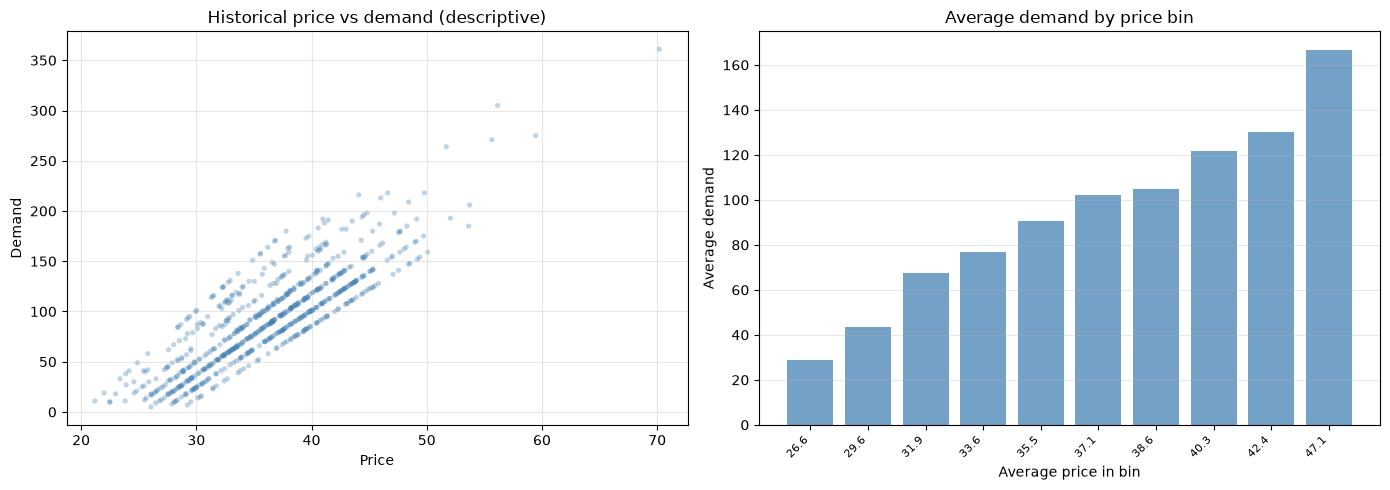

Price bins (average price, average demand, observations):


,Price_Bin,Avg_Price,Avg_Demand,Observations
0,26.6,26.634156,28.688312,77
1,29.6,29.632933,43.666667,75
2,31.9,31.900541,67.635135,74
3,33.6,33.602933,77.026667,75
4,35.5,35.529211,90.434211,76
5,37.1,37.149342,102.157895,76
6,38.6,38.648421,104.710526,76
7,40.3,40.254521,121.506849,73
8,42.4,42.370800,130.053333,75
9,47.1,47.120395,166.592105,76


DESCRIPTIVE CORRELATION (price, demand)
Observations used : 753
Pearson           : +0.8578
Spearman (rank)   : +0.8432

Observed price-demand relationships may be confounded by promotions, seasonality, inventory, product mix, and other business factors. These coefficients are descriptive analysis only and are NOT interpreted as causal effects.


In [7]:
valid = product_history[[PRICE_COLUMN, DEMAND_COLUMN]].apply(pd.to_numeric, errors="coerce").dropna()
valid = valid[(valid[PRICE_COLUMN] > 0) & (valid[DEMAND_COLUMN] >= 0)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- 1) scatter -------------------------------------------------------------
ax = axes[0]
if len(valid) > 3000:
    scatter_sample = valid.sample(n=3000, random_state=RANDOM_STATE)
else:
    scatter_sample = valid
ax.scatter(scatter_sample[PRICE_COLUMN], scatter_sample[DEMAND_COLUMN],
           s=14, alpha=0.35, color="steelblue", edgecolor="none")
ax.set_xlabel("Price")
ax.set_ylabel("Demand")
ax.set_title("Historical price vs demand (descriptive)")
ax.grid(alpha=0.3)

# --- 2) price bins ----------------------------------------------------------
n_bins = int(min(10, valid[PRICE_COLUMN].nunique()))
bin_edges = np.unique(valid[PRICE_COLUMN].quantile(np.linspace(0, 1, n_bins + 1)).to_numpy(dtype=float))
bins_table = pd.DataFrame()
if bin_edges.size >= 2:
    grouped = valid.groupby(pd.cut(valid[PRICE_COLUMN], bins=bin_edges, include_lowest=True),
                            observed=True)
    bins_table = grouped.agg(
        Avg_Price=(PRICE_COLUMN, "mean"),
        Avg_Demand=(DEMAND_COLUMN, "mean"),
        Observations=(PRICE_COLUMN, "size"),
    ).reset_index(drop=True)
    bins_table.insert(0, "Price_Bin", [f"{row.Avg_Price:,.1f}" for row in bins_table.itertuples()])

    ax2 = axes[1]
    ax2.bar(range(len(bins_table)), bins_table["Avg_Demand"], color="steelblue", alpha=0.75)
    ax2.set_xticks(range(len(bins_table)))
    ax2.set_xticklabels(bins_table["Price_Bin"], rotation=45, ha="right", fontsize=8)
    ax2.set_xlabel("Average price in bin")
    ax2.set_ylabel("Average demand")
    ax2.set_title("Average demand by price bin")
    ax2.grid(alpha=0.3, axis="y")
else:
    axes[1].text(0.5, 0.5, "Not enough distinct prices to bin",
                 ha="center", va="center", transform=axes[1].transAxes)

plt.tight_layout()
plt.show()

print("Price bins (average price, average demand, observations):")
display(bins_table if not bins_table.empty else pd.DataFrame({"Note": ["no bins available"]}))

pearson = valid[PRICE_COLUMN].corr(valid[DEMAND_COLUMN])
spearman = valid[PRICE_COLUMN].corr(valid[DEMAND_COLUMN], method="spearman")
print("=" * 78)
print("DESCRIPTIVE CORRELATION (price, demand)")
print("=" * 78)
print(f"Observations used : {len(valid):,}")
print(f"Pearson           : {pearson:+.4f}")
print(f"Spearman (rank)   : {spearman:+.4f}")
print()
print("Observed price-demand relationships may be confounded by promotions, seasonality, inventory, "
      "product mix, and other business factors. These coefficients are descriptive analysis only and "
      "are NOT interpreted as causal effects.")


## 8. Price Elasticity Estimation

A transparent, auditable **log-log regression** on positive price and demand observations:

```
log(Demand) = alpha + beta * log(Price) + error        beta = price elasticity estimate
```

`beta` is reported with its standard error, a 95% confidence interval, R-squared and the number of
observations, then put through explicit reliability checks:

| Check | Fails when |
|-------|------------|
| price variation | series quality is `LIMITED` or `INSUFFICIENT` |
| sign | `beta > 0` - demand rising with price is not a usable pricing relation for a normal good (confounding / data artifacts) |
| magnitude | `beta` outside `[ELASTICITY_MIN, ELASTICITY_MAX]` |
| stability | the 95% confidence interval includes 0 |
| explanatory power | R-squared below `ELASTICITY_R2_MIN` |

**If any check fails, the raw estimate is NOT trusted.** The engine falls back to the configurable
`DEFAULT_ELASTICITY`, labelled:

> **"Scenario elasticity assumption - not causally estimated."**

Either way, `ELASTICITY_USED` and `ELASTICITY_SOURCE` are carried into every downstream number, so it
is always visible whether a result came from an estimate or from an assumption.

In [8]:
def estimate_price_elasticity(frame, price_column, demand_column,
                              min_observations=MIN_ELASTICITY_OBS, confidence_z=CONFIDENCE_Z):
    """OLS of log(Demand) on log(Price). `beta` is the price elasticity estimate.

    Observational association only: it is not a causally identified elasticity.
    """
    data = frame[[price_column, demand_column]].apply(pd.to_numeric, errors="coerce").dropna()
    data = data[(data[price_column] > 0) & (data[demand_column] > 0)]
    n = len(data)
    if n < min_observations:
        return {"available": False, "n": int(n),
                "reason": f"only {n} positive Price/Demand observations (need {min_observations})"}

    x = np.log(data[price_column].to_numpy(dtype=float))
    y = np.log(data[demand_column].to_numpy(dtype=float))
    design = np.column_stack([np.ones(n), x])
    coef, *_ = np.linalg.lstsq(design, y, rcond=None)
    residual = y - design @ coef
    ss_res = float(np.sum(residual ** 2))
    ss_tot = float(np.sum((y - y.mean()) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    sigma2 = ss_res / max(n - 2, 1)
    sxx = float(np.sum((x - x.mean()) ** 2))
    std_error = float(np.sqrt(sigma2 / sxx)) if sxx > 0 else np.nan
    beta = float(coef[1])
    return {
        "available": True,
        "n": int(n),
        "alpha": float(coef[0]),
        "beta": beta,
        "std_error": std_error,
        "ci_low": beta - confidence_z * std_error,
        "ci_high": beta + confidence_z * std_error,
        "r2": float(r2),
        "log_price_mean": float(x.mean()),
        "log_demand_mean": float(y.mean()),
    }


def assess_elasticity_reliability(estimate, price_quality_verdict):
    """Return the list of failed reliability checks (empty list = usable estimate)."""
    issues = []
    if not estimate.get("available"):
        issues.append("estimate unavailable: " + estimate.get("reason", "not enough data"))
        return issues

    beta = estimate["beta"]
    if price_quality_verdict == "INSUFFICIENT":
        issues.append("historical price variation is INSUFFICIENT")
    elif price_quality_verdict == "LIMITED":
        issues.append("historical price variation is LIMITED")
    if beta > 0:
        issues.append("estimated elasticity is POSITIVE (implausible for a normal good - "
                      "price and demand are confounded, so the sign cannot be used for pricing)")
    elif beta > ELASTICITY_MAX:
        issues.append(f"estimated elasticity {beta:+.3f} is weaker than the plausible band "
                      f"(ELASTICITY_MAX = {ELASTICITY_MAX})")
    if beta < ELASTICITY_MIN:
        issues.append(f"estimated elasticity {beta:+.3f} is more extreme than the plausible band "
                      f"(ELASTICITY_MIN = {ELASTICITY_MIN})")
    if np.isfinite(estimate["std_error"]) and estimate["ci_low"] <= 0 <= estimate["ci_high"]:
        issues.append(f"95% confidence interval [{estimate['ci_low']:+.3f}, {estimate['ci_high']:+.3f}] "
                      "includes 0 - the sign is unstable")
    if np.isfinite(estimate["r2"]) and estimate["r2"] < ELASTICITY_R2_MIN:
        issues.append(f"log-log fit explains only {estimate['r2']:.1%} of demand variance "
                      f"(R2_MIN = {ELASTICITY_R2_MIN:.0%})")
    return issues


ELASTICITY_ESTIMATE = estimate_price_elasticity(product_history, PRICE_COLUMN, DEMAND_COLUMN)
ELASTICITY_ISSUES = assess_elasticity_reliability(ELASTICITY_ESTIMATE, PRICE_QUALITY)
ELASTICITY_RELIABLE = len(ELASTICITY_ISSUES) == 0

print("=" * 78)
print("PRICE ELASTICITY ESTIMATION  (log-log OLS: log(Demand) = alpha + beta * log(Price))")
print("=" * 78)
if ELASTICITY_ESTIMATE.get("available"):
    print(f"Observations used : {ELASTICITY_ESTIMATE['n']:,} (Price > 0 and Demand > 0)")
    print(f"Estimated beta    : {ELASTICITY_ESTIMATE['beta']:+.4f}")
    print(f"Standard error    : {ELASTICITY_ESTIMATE['std_error']:.4f}")
    print(f"95% confidence    : [{ELASTICITY_ESTIMATE['ci_low']:+.4f}, "
          f"{ELASTICITY_ESTIMATE['ci_high']:+.4f}]")
    print(f"R-squared         : {ELASTICITY_ESTIMATE['r2']:.4f}")
    print(f"Data quality      : {PRICE_QUALITY}")
else:
    print("No estimate available: " + ELASTICITY_ESTIMATE.get("reason", "unknown"))

print("-" * 78)
print("RELIABILITY CHECKS")
if ELASTICITY_RELIABLE:
    print("  [PASS] all checks passed - the historical estimate is usable as an observational input")
else:
    for issue in ELASTICITY_ISSUES:
        print("  [FAIL] " + issue)

print("-" * 78)
if ELASTICITY_RELIABLE:
    ELASTICITY_USED = float(np.clip(ELASTICITY_ESTIMATE["beta"], ELASTICITY_MIN, ELASTICITY_MAX))
    ELASTICITY_ORIGIN = "estimated"
    ELASTICITY_SOURCE = (f"Historical log-log estimate (observational, n="
                         f"{ELASTICITY_ESTIMATE['n']:,}, R2={ELASTICITY_ESTIMATE['r2']:.3f})")
    print(f"ELASTICITY USED  : {ELASTICITY_USED:+.4f}")
    print(f"ELASTICITY SOURCE: {ELASTICITY_SOURCE}")
    print("Note: even a passing estimate is observational - promotions, seasonality, inventory and "
          "competition may still confound it.")
else:
    ELASTICITY_USED = float(DEFAULT_ELASTICITY)
    ELASTICITY_ORIGIN = "assumed"
    ELASTICITY_SOURCE = (f"Scenario elasticity assumption (DEFAULT_ELASTICITY = {DEFAULT_ELASTICITY}) "
                         f"- not causally estimated")
    print(f"HISTORICAL ESTIMATE REJECTED: {ELASTICITY_ISSUES}")
    print(f"ELASTICITY USED  : {ELASTICITY_USED:+.4f}")
    print(f"ELASTICITY SOURCE: {ELASTICITY_SOURCE}")
    print("The raw estimate is not trusted, so the configurable business assumption is used for all "
          "scenario simulations below.")

assert ELASTICITY_ORIGIN in {"estimated", "assumed"}, "elasticity origin must be identified"
assert ELASTICITY_MIN <= ELASTICITY_USED <= ELASTICITY_MAX, "elasticity used must lie in the plausible band"


PRICE ELASTICITY ESTIMATION  (log-log OLS: log(Demand) = alpha + beta * log(Price))
Observations used : 753 (Price > 0 and Demand > 0)
Estimated beta    : +3.2712
Standard error    : 0.0797
95% confidence    : [+3.1150, +3.4273]
R-squared         : 0.6918
Data quality      : GOOD
------------------------------------------------------------------------------
RELIABILITY CHECKS
  [FAIL] estimated elasticity is POSITIVE (implausible for a normal good - price and demand are confounded, so the sign cannot be used for pricing)
------------------------------------------------------------------------------
HISTORICAL ESTIMATE REJECTED: ['estimated elasticity is POSITIVE (implausible for a normal good - price and demand are confounded, so the sign cannot be used for pricing)']
ELASTICITY USED  : -1.5000
ELASTICITY SOURCE: Scenario elasticity assumption (DEFAULT_ELASTICITY = -1.5) - not causally estimated
The raw estimate is not trusted, so the configurable business assumption is used for all sc

## 9. Demand Model Baseline Prediction (stage 1 of 4)

The most recent observation of the selected series is passed **as it is** to the saved pipeline. The
feature schema is taken from `model_metadata.json` (`feature_columns`) - the old hardcoded 29-feature
list is never rebuilt by hand. Lag features (`Previous_Demand`, `Previous_Price`, ...) are whatever they
were on that historical date, so nothing from the future leaks into the baseline.

This gives `BASELINE_DEMAND`: the model's expected demand **at the current price and current conditions**.
Everything later in the notebook is expressed relative to this baseline.

Note what is *not* done here: the model is not re-run on counterfactual prices. Feeding modified prices
into a forecasting model and reading the difference as "the effect of price" would silently assume the
model is causal - it is not. Price changes are handled in stage 3 by an explicit, transparent formula.

In [9]:
MODEL_FEATURES = list(FEATURE_COLUMNS_FROM_METADATA)

if not MODEL_FEATURES:
    raise ValueError("model_metadata.json does not declare feature_columns - cannot build model input.")
missing_features = [feature for feature in MODEL_FEATURES if feature not in df.columns]
if missing_features:
    raise ValueError(
        "The saved pipeline expects feature column(s) that are absent from the dataset: "
        + ", ".join(missing_features)
    )


def prepare_model_input(row, features):
    """Select exactly the columns of the saved pipeline's input contract (from metadata)."""
    return row[features].copy()


current_row = product_history.iloc[[-1]].copy()
X_current = prepare_model_input(current_row, MODEL_FEATURES)

raw_prediction = np.asarray(model.predict(X_current), dtype=float).ravel()
BASELINE_DEMAND = float(max(raw_prediction[0], 0.0))          # demand cannot be negative

CURRENT_PRICE = float(pd.to_numeric(current_row[PRICE_COLUMN], errors="coerce").iloc[0])
CURRENT_DEMAND = float(pd.to_numeric(current_row[DEMAND_COLUMN], errors="coerce").iloc[0])
if not np.isfinite(CURRENT_PRICE) or CURRENT_PRICE <= 0:
    raise ValueError(f"Current price must be strictly positive to build scenarios (got {CURRENT_PRICE}).")

CURRENT_DISCOUNT_PCT = 0.0
if BUSINESS_COLUMNS.get("Discount"):
    raw_discount = float(pd.to_numeric(current_row[BUSINESS_COLUMNS["Discount"]], errors="coerce").iloc[0])
    if np.isfinite(raw_discount) and 0.0 <= raw_discount <= 100.0:
        CURRENT_DISCOUNT_PCT = raw_discount
    elif np.isfinite(raw_discount):
        print(f"WARNING: Discount value {raw_discount} is outside 0-100 and was ignored "
              "(the canonical schema stores discounts as a percentage).")
CURRENT_EFFECTIVE_PRICE = CURRENT_PRICE * (1.0 - CURRENT_DISCOUNT_PCT / 100.0)

CURRENT_REVENUE = CURRENT_EFFECTIVE_PRICE * BASELINE_DEMAND
CURRENT_PROFIT = ((CURRENT_EFFECTIVE_PRICE - UNIT_COST) * BASELINE_DEMAND
                  if UNIT_COST is not None else None)


def snapshot_value(canonical):
    """Value of an optional business column on the current row, '-' when unavailable."""
    column = BUSINESS_COLUMNS.get(canonical)
    if not column:
        return "-"
    value = current_row[column].iloc[0]
    if isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool):
        return f"{float(value):,.2f}" if np.isfinite(value) else "-"
    return str(value)


print("=" * 78)
print("BASELINE SNAPSHOT  (stage 1 - demand prediction, no price change applied)")
print("=" * 78)
print(f"{'Date':<34}: " + (f"{current_row[DATE_COLUMN].iloc[0]:%Y-%m-%d}" if DATE_COLUMN else "-"))
for key in SERIES_KEYS:
    print(f"{key:<34}: {SELECTED_SERIES[key]}")
print(f"{'Current Price (list)':<34}: {CURRENT_PRICE:,.2f}")
print(f"{'Current Discount (%)':<34}: {CURRENT_DISCOUNT_PCT:,.2f}")
print(f"{'Current Effective Price':<34}: {CURRENT_EFFECTIVE_PRICE:,.2f}")
print(f"{'Current Demand (observed)':<34}: {CURRENT_DEMAND:,.2f}")
print(f"{'Predicted Baseline Demand':<34}: {BASELINE_DEMAND:,.2f}")
print(f"{'Unit Cost':<34}: " + (f"{UNIT_COST:,.2f}" if UNIT_COST is not None
                                else "not available (revenue optimization)"))
print(f"{'Competitor Price':<34}: " + snapshot_value("Competitor_Price"))
print(f"{'Inventory':<34}: " + snapshot_value("Inventory"))
print(f"{'Promotion':<34}: " + snapshot_value("Promotion"))
print(f"{'Category':<34}: " + snapshot_value("Category"))
print(f"{'Region':<34}: " + snapshot_value("Region"))
print("-" * 78)
print(f"Model input contract: {len(MODEL_FEATURES)} feature columns from model_metadata.json")
print("Contract preview (first 12 columns of the row sent to the pipeline):")
display(X_current[MODEL_FEATURES[:12]].T.rename(columns={X_current.index[0]: "value"}))
print("Demand target column is NOT part of the model input - it is shown above as observed context only."
      if DEMAND_COLUMN not in MODEL_FEATURES else "WARNING: target column present among model features.")


BASELINE SNAPSHOT  (stage 1 - demand prediction, no price change applied)
Date                              : 2024-01-30
Product_ID                        : P0006
Store_ID                          : S003
Current Price (list)              : 48.42
Current Discount (%)              : 0.00
Current Effective Price           : 48.42
Current Demand (observed)         : 147.00
Predicted Baseline Demand         : 140.53
Unit Cost                         : not available (revenue optimization)
Competitor Price                  : 42.97
Inventory                         : 156.00
Promotion                         : 0.00
Category                          : Toys
Region                            : East
------------------------------------------------------------------------------
Model input contract: 32 feature columns from model_metadata.json
Contract preview (first 12 columns of the row sent to the pipeline):


,value
Store_ID,S003
Product_ID,P0006
Category,Toys
Region,East
Inventory,156.0
Price,48.42
Discount,0.0
Weather,Sunny
Promotion,0
Competitor_Price,42.97


Demand target column is NOT part of the model input - it is shown above as observed context only.


## 10. Price Scenario Generation

The search space is taken from the product's **own historical price distribution**, never from arbitrary
values:

```
min_price = product_history["Price"].quantile(0.05)
max_price = product_history["Price"].quantile(0.95)
```

`N_SCENARIOS` evenly spaced prices are generated between those bounds. Optimizing outside the historical
range would extrapolate far beyond anything ever observed, so it is off-limits by design. The current
price is reported relative to that range (it can sit outside the 5th-95th percentile window, which is
itself useful business information).

In [10]:
min_price = float(product_history[PRICE_COLUMN].quantile(PRICE_LOW_QUANTILE))
max_price = float(product_history[PRICE_COLUMN].quantile(PRICE_HIGH_QUANTILE))
hist_min = float(pd.to_numeric(product_history[PRICE_COLUMN], errors="coerce").min())
hist_max = float(pd.to_numeric(product_history[PRICE_COLUMN], errors="coerce").max())

if not (np.isfinite(min_price) and np.isfinite(max_price)) or max_price <= min_price:
    print(f"Quantile range [{min_price}, {max_price}] is degenerate - falling back to the observed "
          f"price range [{hist_min}, {hist_max}].")
    min_price, max_price = hist_min, hist_max

if not (np.isfinite(min_price) and np.isfinite(max_price)) or min_price <= 0 or max_price < min_price:
    raise ValueError("Cannot build a usable price scenario range from the historical prices "
                     f"(min={min_price}, max={max_price}). Check the Price column.")

SCENARIO_PRICES = np.linspace(min_price, max_price, N_SCENARIOS)
SCENARIO_MIN, SCENARIO_MAX = float(SCENARIO_PRICES.min()), float(SCENARIO_PRICES.max())

print("=" * 78)
print("PRICE SCENARIO GRID")
print("=" * 78)
print(f"Historical price range (all observations) : {hist_min:,.2f} - {hist_max:,.2f}")
print(f"Search space ({PRICE_LOW_QUANTILE:.0%}-{PRICE_HIGH_QUANTILE:.0%} quantiles)  : "
      f"{min_price:,.2f} - {max_price:,.2f}")
print(f"Scenarios generated                      : {N_SCENARIOS} evenly spaced prices "
      f"({SCENARIO_MIN:,.2f} -> {SCENARIO_MAX:,.2f})")
print(f"Current price                            : {CURRENT_PRICE:,.2f}", end="")
if SCENARIO_MIN <= CURRENT_PRICE <= SCENARIO_MAX:
    print("  (inside the search space)")
else:
    print("  (OUTSIDE the scenario range - the current price is unusual for this series; "
          "all changes are still bounded by the guardrails)")


PRICE SCENARIO GRID
Historical price range (all observations) : 21.19 - 70.18
Search space (5%-95% quantiles)  : 27.22 - 45.64
Scenarios generated                      : 30 evenly spaced prices (27.22 -> 45.64)
Current price                            : 48.42  (OUTSIDE the scenario range - the current price is unusual for this series; all changes are still bounded by the guardrails)


## 11. Scenario Demand Simulation (stage 3 of 4)

For every candidate price the notebook starts from the **baseline model prediction** and applies a
transparent constant-elasticity formula:

```python
price_ratio    = scenario_price / current_price
adjusted_demand = baseline_demand * (price_ratio ** elasticity)
```

This is **elasticity-adjusted scenario demand** - a deliberately simple, auditable business rule.

> **What this cell is NOT doing:** the forecasting model is *not* re-run on counterfactual prices, and
> the model has *not* learned causal price elasticity. The ML model predicts demand under historical
> conditions; the price response comes from `ELASTICITY_USED`, which is either an observational estimate
> or a stated assumption (see stage 2). Demand is clipped at 0 - a scenario can never be negative.

In [11]:
def adjust_demand(prices, current_price, baseline_demand, elasticity):
    """Elasticity-adjusted scenario demand.

        adjusted_demand = baseline_demand * (scenario_price / current_price) ** elasticity

    Transparent scenario rule - NOT a causal effect estimated by the forecasting model.
    Returns a non-negative array by construction (positive baseline, positive price ratio).
    """
    prices = np.asarray(prices, dtype=float)
    ratio = np.clip(prices / float(current_price), 1e-9, None)
    demand = float(baseline_demand) * np.power(ratio, float(elasticity))
    return np.clip(demand, 0.0, None)


def build_scenario_table(prices, elasticity, baseline_demand, current_price, discount_pct):
    """Demand-side scenario table: price, price ratio, effective price, adjusted demand."""
    scen = pd.DataFrame({"Price": np.asarray(prices, dtype=float)})
    scen["Price_Change_Pct"] = (scen["Price"] - current_price) / current_price * 100.0
    scen["Price_Ratio"] = scen["Price"] / current_price
    scen["Effective_Price"] = scen["Price"] * (1.0 - discount_pct / 100.0)
    scen["Adjusted_Demand"] = adjust_demand(scen["Price"], current_price, baseline_demand, elasticity)
    return scen


scenarios = build_scenario_table(SCENARIO_PRICES, ELASTICITY_USED, BASELINE_DEMAND,
                                 CURRENT_PRICE, CURRENT_DISCOUNT_PCT)

print("=" * 78)
print("ELASTICITY-ADJUSTED SCENARIO DEMAND")
print("=" * 78)
print(f"Elasticity applied : {ELASTICITY_USED:+.4f}  ({ELASTICITY_SOURCE})")
print(f"Baseline demand    : {BASELINE_DEMAND:,.2f} units at the current price {CURRENT_PRICE:,.2f}")
print(f"Scenario demand    : {scenarios['Adjusted_Demand'].min():,.2f} - "
      f"{scenarios['Adjusted_Demand'].max():,.2f} units across the price grid")
print(f"Non-negative       : {bool((scenarios['Adjusted_Demand'] >= 0).all())}")
print()
display(scenarios.head(10))


ELASTICITY-ADJUSTED SCENARIO DEMAND
Elasticity applied : -1.5000  (Scenario elasticity assumption (DEFAULT_ELASTICITY = -1.5) - not causally estimated)
Baseline demand    : 140.53 units at the current price 48.42
Scenario demand    : 153.56 - 333.40 units across the price grid
Non-negative       : True



,Price,Price_Change_Pct,Price_Ratio,Effective_Price,Adjusted_Demand
0,27.220000,-43.783561,0.562164,27.220000,333.402257
1,27.855172,-42.471763,0.575282,27.855172,322.063820
2,28.490345,-41.159965,0.588400,28.490345,311.353791
3,29.125517,-39.848168,0.601518,29.125517,301.224468
4,29.760690,-38.536370,0.614636,29.760690,291.632707
5,30.395862,-37.224572,0.627754,30.395862,282.539400
6,31.031034,-35.912775,0.640872,31.031034,273.909021
7,31.666207,-34.600977,0.653990,31.666207,265.709235
8,32.301379,-33.289179,0.667108,32.301379,257.910554
9,32.936552,-31.977382,0.680226,32.936552,250.486038


## 12. Revenue and Profit

```
Revenue = Effective_Price * Adjusted_Demand
Profit  = (Effective_Price - Unit_Cost) * Adjusted_Demand      # only when the business provides a cost
Profit_Margin = Profit / Revenue                               # NaN-safe when revenue is 0
```

`Effective_Price` applies the current observation's discount, which is held constant across scenarios -
changing the discount would be a separate lever and a separate study.

**If `Unit_Cost` is missing, only revenue is calculated.** No arbitrary cost, no "demo" cost, no cost
back-solved from prices is substituted: a profit number built on an invented cost would be worse than
no profit number at all. All cost reasoning is deferred to the clearly labelled *hypothetical* cost
sensitivity section.

In [12]:
def add_financials(scen, unit_cost):
    """Attach Revenue (always) and Profit / Profit_Margin (only with a real business unit cost)."""
    out = scen.copy()
    out["Revenue"] = out["Effective_Price"] * out["Adjusted_Demand"]
    if unit_cost is not None:
        out["Profit"] = (out["Effective_Price"] - float(unit_cost)) * out["Adjusted_Demand"]
        revenue = out["Revenue"].to_numpy(dtype=float)
        profit = out["Profit"].to_numpy(dtype=float)
        margin = np.full(len(out), np.nan)
        positive = np.isfinite(revenue) & (revenue > 0)
        margin[positive] = profit[positive] / revenue[positive]
        out["Profit_Margin"] = margin
    return out


def simulate(prices, elasticity, baseline_demand, current_price, discount_pct, unit_cost):
    """Full scenario simulation: demand adjustment + financials (reused by the sensitivity cells)."""
    demand_side = build_scenario_table(prices, elasticity, baseline_demand, current_price, discount_pct)
    return add_financials(demand_side, unit_cost)


scenarios = simulate(SCENARIO_PRICES, ELASTICITY_USED, BASELINE_DEMAND, CURRENT_PRICE,
                     CURRENT_DISCOUNT_PCT, UNIT_COST)

print("=" * 78)
print("REVENUE / PROFIT BY SCENARIO")
print("=" * 78)
if UNIT_COST is None:
    print("Unit cost is unavailable. Revenue optimization can be performed, but true profit "
          "optimization requires business-provided unit cost.")
    print("No profit column is created - no cost is invented.")
    print(f"Current expected revenue at baseline demand : {CURRENT_REVENUE:,.2f}")
else:
    print(f"Unit cost used              : {UNIT_COST:,.2f} (from column '{UNIT_COST_COLUMN}')")
    print(f"Current expected revenue    : {CURRENT_REVENUE:,.2f}")
    print(f"Current expected profit     : {CURRENT_PROFIT:,.2f}")
    print(f"Current expected margin     : {CURRENT_PROFIT / CURRENT_REVENUE:.2%}"
          if CURRENT_REVENUE > 0 else "Current expected margin: n/a (zero revenue)")

# Cross-check the effective-price formula against the dataset's own column when it exists.
effective_column = BUSINESS_COLUMNS.get("Effective_Price")
if effective_column and effective_column in product_history.columns:
    dataset_effective = pd.to_numeric(current_row[effective_column], errors="coerce").iloc[0]
    if np.isfinite(dataset_effective):
        match = np.isclose(float(dataset_effective), CURRENT_EFFECTIVE_PRICE, rtol=1e-6, atol=1e-6)
        print(f"Effective-price cross-check vs dataset column '{effective_column}': "
              f"{'MATCH' if match else 'MISMATCH'} "
              f"({float(dataset_effective):,.4f} vs {CURRENT_EFFECTIVE_PRICE:,.4f})")

print()
display(scenarios.head(10))


REVENUE / PROFIT BY SCENARIO
Unit cost is unavailable. Revenue optimization can be performed, but true profit optimization requires business-provided unit cost.
No profit column is created - no cost is invented.
Current expected revenue at baseline demand : 6,804.38



,Price,Price_Change_Pct,Price_Ratio,Effective_Price,Adjusted_Demand,Revenue
0,27.220000,-43.783561,0.562164,27.220000,333.402257,9075.209425
1,27.855172,-42.471763,0.575282,27.855172,322.063820,8971.143236
2,28.490345,-41.159965,0.588400,28.490345,311.353791,8870.576864
3,29.125517,-39.848168,0.601518,29.125517,301.224468,8773.318439
4,29.760690,-38.536370,0.614636,29.760690,291.632707,8679.190499
5,30.395862,-37.224572,0.627754,30.395862,282.539400,8588.028633
6,31.031034,-35.912775,0.640872,31.031034,273.909021,8499.680271
7,31.666207,-34.600977,0.653990,31.666207,265.709235,8414.003606
8,32.301379,-33.289179,0.667108,32.301379,257.910554,8330.866642
9,32.936552,-31.977382,0.680226,32.936552,250.486038,8250.146335


## 13. Optimization (stage 4 of 4)

Scenarios are scored on `OPTIMIZATION_BASIS`:

* **Profit mode** (only when the business supplied `Unit_Cost`) - the recommended price is the scenario
  with the highest expected profit.
* **Revenue mode** (this dataset) - the recommended price is the scenario with the highest expected
  revenue, explicitly labelled **"Revenue-maximizing price - not profit-maximizing price."**

Two results are always produced side by side:

1. the **unconstrained optimum** over the scenario grid, and
2. the **guardrail-constrained recommendation** (the best *feasible* scenario).

If the unconstrained optimum breaks a guardrail (a price move beyond `MAX_PRICE_CHANGE_PCT`, a margin
below `MIN_PROFIT_MARGIN`, a demand below `MIN_EXPECTED_DEMAND`), the engine does not recommend it - it
selects the best feasible scenario instead. When no scenario is feasible, the current price is held.

In [13]:
GUARDRAILS = {
    "min_price": MIN_PRICE,
    "max_price": MAX_PRICE,
    "max_price_change_pct": MAX_PRICE_CHANGE_PCT,
    "min_profit_margin": MIN_PROFIT_MARGIN,
    "min_expected_demand": MIN_EXPECTED_DEMAND,
}


def apply_guardrails(scen, current_price, unit_cost, guardrails):
    """Add `Feasible` / `Guardrail_Violation` columns. Returns (table, blocked_counts)."""
    out = scen.copy()
    price = out["Price"].to_numpy(dtype=float)
    lo = guardrails["min_price"] if guardrails["min_price"] is not None else float(price.min())
    hi = guardrails["max_price"] if guardrails["max_price"] is not None else float(price.max())

    within_bounds = (price >= lo - 1e-9) & (price <= hi + 1e-9)
    change_pct = np.abs(price - current_price) / current_price * 100.0
    within_change = change_pct <= guardrails["max_price_change_pct"] + 1e-9

    if guardrails["min_expected_demand"] is not None:
        demand_ok = out["Adjusted_Demand"].to_numpy(dtype=float) >= guardrails["min_expected_demand"]
    else:
        demand_ok = np.ones(len(out), dtype=bool)

    if unit_cost is not None and "Effective_Price" in out.columns:
        effective = out["Effective_Price"].to_numpy(dtype=float)
        margin = np.where(effective > 0, (effective - float(unit_cost)) / effective, -np.inf)
        margin_ok = margin >= guardrails["min_profit_margin"]
    else:
        margin_ok = np.ones(len(out), dtype=bool)

    out["Guardrail_Violation"] = np.select(
        [~within_change, ~within_bounds, ~margin_ok, ~demand_ok],
        [f"price change beyond +/-{guardrails['max_price_change_pct']:.1f}%",
         "outside the configured min/max price",
         f"margin below {guardrails['min_profit_margin']:.0%}",
         "below the minimum expected demand"],
        default="",
    )
    out["Feasible"] = within_change & within_bounds & margin_ok & demand_ok
    blocked = {
        "max_price_change_pct": int((~within_change).sum()),
        "price_bounds": int((~within_bounds).sum()),
        "min_profit_margin": int((~margin_ok).sum()),
        "min_expected_demand": int((~demand_ok).sum()),
    }
    return out, blocked


def pct_change(new_value, old_value):
    """Percentage change, NaN when the reference is missing or zero."""
    if new_value is None or old_value is None:
        return np.nan
    if not np.isfinite(new_value) or not np.isfinite(old_value) or old_value == 0:
        return np.nan
    return (new_value - old_value) / abs(old_value) * 100.0


OBJECTIVE = "Profit" if OPTIMIZATION_BASIS == "profit" else "Revenue"
OBJECTIVE_LABEL = "expected profit" if OBJECTIVE == "Profit" else "expected revenue"

scenarios, GUARDRAIL_BLOCKS = apply_guardrails(scenarios, CURRENT_PRICE, UNIT_COST, GUARDRAILS)
GUARDRAIL_MIN_PRICE = GUARDRAILS["min_price"] if GUARDRAILS["min_price"] is not None else SCENARIO_MIN
GUARDRAIL_MAX_PRICE = GUARDRAILS["max_price"] if GUARDRAILS["max_price"] is not None else SCENARIO_MAX

CURRENT_OBJECTIVE = CURRENT_PROFIT if OBJECTIVE == "Profit" else CURRENT_REVENUE

# --- 1) unconstrained optimum over the scenario grid ------------------------
unconstrained_idx = int(scenarios[OBJECTIVE].idxmax())
UNCONSTRAINED_BEST = scenarios.loc[unconstrained_idx]

# --- 2) best feasible scenario (guardrails applied) -------------------------
feasible_rows = scenarios[scenarios["Feasible"]]
GUARDRAIL_BLOCKED = bool(feasible_rows.empty)

if GUARDRAIL_BLOCKED:
    RECOMMENDED_PRICE = CURRENT_PRICE
    RECOMMENDED_EFFECTIVE_PRICE = CURRENT_EFFECTIVE_PRICE
    RECOMMENDED_DEMAND = BASELINE_DEMAND
    RECOMMENDED_REVENUE = CURRENT_REVENUE
    RECOMMENDED_PROFIT = CURRENT_PROFIT
    RECOMMENDED_OBJECTIVE = CURRENT_OBJECTIVE
    MAX_FEASIBLE_OBJECTIVE = None
    best_feasible = None
else:
    best_feasible = feasible_rows.loc[int(feasible_rows[OBJECTIVE].idxmax())]
    RECOMMENDED_PRICE = float(best_feasible["Price"])
    RECOMMENDED_EFFECTIVE_PRICE = float(best_feasible["Effective_Price"])
    RECOMMENDED_DEMAND = float(best_feasible["Adjusted_Demand"])
    RECOMMENDED_REVENUE = float(best_feasible["Revenue"])
    RECOMMENDED_PROFIT = float(best_feasible["Profit"]) if "Profit" in best_feasible else None
    RECOMMENDED_OBJECTIVE = float(best_feasible[OBJECTIVE])
    MAX_FEASIBLE_OBJECTIVE = float(feasible_rows[OBJECTIVE].max())

IMPROVEMENT_ABS = RECOMMENDED_OBJECTIVE - CURRENT_OBJECTIVE
IMPROVEMENT_PCT = pct_change(RECOMMENDED_OBJECTIVE, CURRENT_OBJECTIVE)

# --- comparison --------------------------------------------------------------
print("=" * 78)
print(f"OPTIMIZATION RESULT  (basis: {OBJECTIVE_LABEL}; "
      f"elasticity {ELASTICITY_USED:+.3f} - {ELASTICITY_ORIGIN})")
print("=" * 78)

comparison_rows = [
    ("Price (list)", CURRENT_PRICE, RECOMMENDED_PRICE),
    ("Effective price", CURRENT_EFFECTIVE_PRICE, RECOMMENDED_EFFECTIVE_PRICE),
    ("Expected demand", BASELINE_DEMAND, RECOMMENDED_DEMAND),
    ("Expected revenue", CURRENT_REVENUE, RECOMMENDED_REVENUE),
]
if OBJECTIVE == "Profit":
    comparison_rows.append(("Expected profit", CURRENT_PROFIT, RECOMMENDED_PROFIT))
    if CURRENT_REVENUE and RECOMMENDED_REVENUE:
        comparison_rows.append(("Expected margin",
                                CURRENT_PROFIT / CURRENT_REVENUE,
                                RECOMMENDED_PROFIT / RECOMMENDED_REVENUE))

print(f"{'':<22}{'Current':>15}{'Recommended':>15}{'Change':>13}")
for label, current_value, recommended_value in comparison_rows:
    change_text = "n/a"
    change_value = pct_change(recommended_value, current_value)
    if np.isfinite(change_value):
        change_text = f"{change_value:+.2f}%"
    if "margin" in label.lower():
        current_text = f"{current_value:.2%}"
        recommended_text = f"{recommended_value:.2%}"
    else:
        current_text = f"{current_value:,.2f}"
        recommended_text = f"{recommended_value:,.2f}"
    print(f"{label:<22}{current_text:>15}{recommended_text:>15}{change_text:>13}")

print("-" * 78)
print(f"Unconstrained optimum : price {UNCONSTRAINED_BEST['Price']:,.2f} "
      f"({UNCONSTRAINED_BEST['Price_Change_Pct']:+.2f}%) -> {OBJECTIVE} "
      f"{UNCONSTRAINED_BEST[OBJECTIVE]:,.2f}"
      f"  [feasible: {'yes' if UNCONSTRAINED_BEST['Feasible'] else 'NO'}]")
if GUARDRAIL_BLOCKED:
    print("Guardrails            : NO scenario satisfies the configured guardrails - holding the "
          "current price as the recommendation.")
elif abs(UNCONSTRAINED_BEST["Price"] - RECOMMENDED_PRICE) > 1e-9:
    print(f"Guardrails            : unconstrained optimum rejected "
          f"({UNCONSTRAINED_BEST['Guardrail_Violation']}); best feasible scenario used instead: "
          f"{RECOMMENDED_PRICE:,.2f}")
else:
    print("Guardrails            : unconstrained optimum already satisfies every guardrail.")
print(f"Feasible scenarios    : {int(scenarios['Feasible'].sum())} of {len(scenarios)}")
print(f"Improvement in {OBJECTIVE_LABEL:<16}: {IMPROVEMENT_ABS:+,.2f} "
      f"({IMPROVEMENT_PCT:+.2f}%)" if np.isfinite(IMPROVEMENT_PCT)
      else f"Improvement in {OBJECTIVE_LABEL}: {IMPROVEMENT_ABS:+,.2f}")


OPTIMIZATION RESULT  (basis: expected revenue; elasticity -1.500 - assumed)
                              Current    Recommended       Change
Price (list)                    48.42          43.73       -9.68%
Effective price                 48.42          43.73       -9.68%
Expected demand                140.53         163.71      +16.49%
Expected revenue             6,804.38       7,159.60       +5.22%
------------------------------------------------------------------------------
Unconstrained optimum : price 27.22 (-43.78%) -> Revenue 9,075.21  [feasible: NO]
Guardrails            : unconstrained optimum rejected (price change beyond +/-10.0%); best feasible scenario used instead: 43.73
Feasible scenarios    : 4 of 30
Improvement in expected revenue: +355.22 (+5.22%)


## 14. Business Decision Logic

`decide_pricing_action()` converts the numbers into one of five explicit outcomes, evaluated in order:

| # | Condition | Action |
|---|-----------|--------|
| 1 | historical price variation is insufficient | **INSUFFICIENT_DATA** - scenario analysis only, hold the price |
| 2 | profit mode and the maximum achievable profit <= 0 | **NO_GO** - no price in the tested range is expected to be profitable |
| 3 | the best feasible scenario does not improve the objective | **KEEP** - changing the price buys nothing |
| 4 | recommended price > current price | **RAISE** |
| 5 | recommended price < current price | **LOWER** |
| 6 | revenue-only optimization | identical logic, but every message is labelled *"Revenue-maximizing price - not profit-maximizing price"* |

A price is never recommended just because it is mathematically the maximum: if every available price
produces a loss, the honest answer is `NO_GO`.

In [14]:
def decide_pricing_action(data_quality, optimization_basis, current_price, recommended_price,
                          current_objective, max_feasible_objective, improvement_abs,
                          improvement_pct=None, guardrail_blocked=False,
                          min_improvement_pct=MIN_IMPROVEMENT_PCT):
    """Map an optimization result to a business action: KEEP / RAISE / LOWER / NO_GO / INSUFFICIENT_DATA.

    Pure decision rules - no price is recommended merely because it is the mathematical maximum.
    """
    objective_name = "profit" if optimization_basis == "profit" else "revenue"
    result = {
        "action": None,
        "reason": "",
        "objective": objective_name,
        "basis_label": ("Profit maximization using the business-provided unit cost"
                        if optimization_basis == "profit"
                        else "Revenue-maximizing price - not profit-maximizing price"),
    }

    # 1) data cannot support a price response
    if data_quality == "INSUFFICIENT":
        result["action"] = "INSUFFICIENT_DATA"
        result["reason"] = ("Historical price variation is insufficient for reliable price-response "
                            "estimation, so the output is scenario analysis only and the current "
                            "price is held.")
        return result

    # 2) every tested price loses money
    if (optimization_basis == "profit" and max_feasible_objective is not None
            and max_feasible_objective <= 0):
        result["action"] = "NO_GO"
        result["reason"] = ("No price within the tested historical range is expected to generate "
                            "positive profit under the current assumptions.")
        return result

    # 3) no improvement over the current price
    improves = improvement_abs is not None and improvement_abs > 0
    if improvement_pct is not None and np.isfinite(improvement_pct) and improvement_pct <= min_improvement_pct:
        improves = False
    if not improves:
        result["action"] = "KEEP"
        result["reason"] = (f"The best feasible scenario does not improve expected {objective_name} "
                            "over the current price.")
        if guardrail_blocked:
            result["reason"] += " No candidate price satisfied the configured guardrails."
        return result

    # 4)/5) direction of the change
    if recommended_price > current_price:
        result["action"] = "RAISE"
        result["reason"] = (f"The best feasible scenario sets a higher price than the current one "
                            f"(+{(recommended_price / current_price - 1) * 100:.2f}%), improving "
                            f"expected {objective_name} under the stated assumptions.")
    elif recommended_price < current_price:
        result["action"] = "LOWER"
        result["reason"] = (f"The best feasible scenario sets a lower price than the current one "
                            f"({(recommended_price / current_price - 1) * 100:.2f}%), improving "
                            f"expected {objective_name} under the stated assumptions.")
    else:
        result["action"] = "KEEP"
        result["reason"] = (f"The recommended price equals the current price, so expected "
                            f"{objective_name} is unchanged.")
    return result


DECISION = decide_pricing_action(
    data_quality=PRICE_QUALITY,
    optimization_basis=OPTIMIZATION_BASIS,
    current_price=CURRENT_PRICE,
    recommended_price=RECOMMENDED_PRICE,
    current_objective=CURRENT_OBJECTIVE,
    max_feasible_objective=MAX_FEASIBLE_OBJECTIVE,
    improvement_abs=IMPROVEMENT_ABS,
    improvement_pct=IMPROVEMENT_PCT,
    guardrail_blocked=GUARDRAIL_BLOCKED,
)
ACTION = DECISION["action"]
ACTION_REASON = DECISION["reason"]
OPTIMIZATION_BASIS_LABEL = DECISION["basis_label"]

VALID_ACTIONS = {"KEEP", "RAISE", "LOWER", "NO_GO", "INSUFFICIENT_DATA"}
assert ACTION in VALID_ACTIONS, f"unexpected action {ACTION!r}"

print("=" * 78)
print("BUSINESS DECISION")
print("=" * 78)
print(f"Action        : {ACTION}")
print(f"Reason        : {ACTION_REASON}")
print(f"Objective     : {DECISION['objective']}")
print(f"Basis         : {OPTIMIZATION_BASIS_LABEL}")
print(f"Elasticity    : {ELASTICITY_USED:+.4f} ({ELASTICITY_ORIGIN})")
print(f"Data quality  : {PRICE_QUALITY}")


BUSINESS DECISION
Action        : LOWER
Reason        : The best feasible scenario sets a lower price than the current one (-9.68%), improving expected revenue under the stated assumptions.
Objective     : revenue
Basis         : Revenue-maximizing price - not profit-maximizing price
Elasticity    : -1.5000 (assumed)
Data quality  : GOOD


## 15. Price vs Expected Demand

The scenario curve: expected demand at each candidate price, with the historical observations as light
context, plus the current point and the recommended point.

Title: **"Elasticity-Adjusted Demand Scenarios"** - it is a scenario curve produced by the elasticity
formula, *not* a causally estimated demand curve.

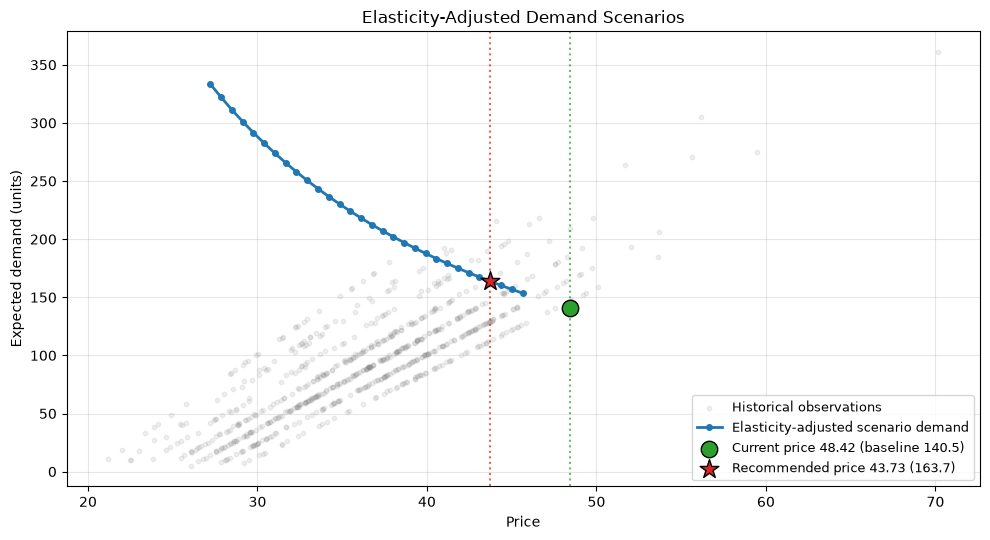

Elasticity used: -1.5000 (assumed)
Curve = baseline model forecast x (price / current price) ** elasticity.
This is a scenario model for decision support - it is NOT a causally estimated demand curve.


In [15]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.scatter(product_history[PRICE_COLUMN], product_history[DEMAND_COLUMN],
           s=10, alpha=0.12, color="gray", label="Historical observations")
ax.plot(scenarios["Price"], scenarios["Adjusted_Demand"], color="tab:blue", lw=2, marker="o", ms=4,
        label="Elasticity-adjusted scenario demand")
ax.axvline(CURRENT_PRICE, color="tab:green", ls=":", alpha=0.7)
ax.scatter([CURRENT_PRICE], [BASELINE_DEMAND], s=140, color="tab:green", zorder=5,
           edgecolor="black",
           label=f"Current price {CURRENT_PRICE:,.2f} (baseline {BASELINE_DEMAND:,.1f})")
if abs(RECOMMENDED_PRICE - CURRENT_PRICE) > 1e-9:
    ax.axvline(RECOMMENDED_PRICE, color="tab:red", ls=":", alpha=0.7)
ax.scatter([RECOMMENDED_PRICE], [RECOMMENDED_DEMAND], s=200, marker="*", color="tab:red", zorder=6,
           edgecolor="black",
           label=f"Recommended price {RECOMMENDED_PRICE:,.2f} ({RECOMMENDED_DEMAND:,.1f})")

ax.set_xlabel("Price")
ax.set_ylabel("Expected demand (units)")
ax.set_title("Elasticity-Adjusted Demand Scenarios")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Elasticity used: {ELASTICITY_USED:+.4f} ({ELASTICITY_ORIGIN})")
print("Curve = baseline model forecast x (price / current price) ** elasticity.")
print("This is a scenario model for decision support - it is NOT a causally estimated demand curve.")


## 16. Price vs Expected Revenue / Profit

Objective curve over the same scenario grid, with three markers:

* **Current price** - the reference point,
* **Recommended price** - the guardrail-feasible optimum actually proposed,
* grey hollow markers - scenarios rejected by a guardrail.

If `Unit_Cost` exists the chart is *Price vs Expected Profit*; otherwise it is *Price vs Expected
Revenue* and every label says so.

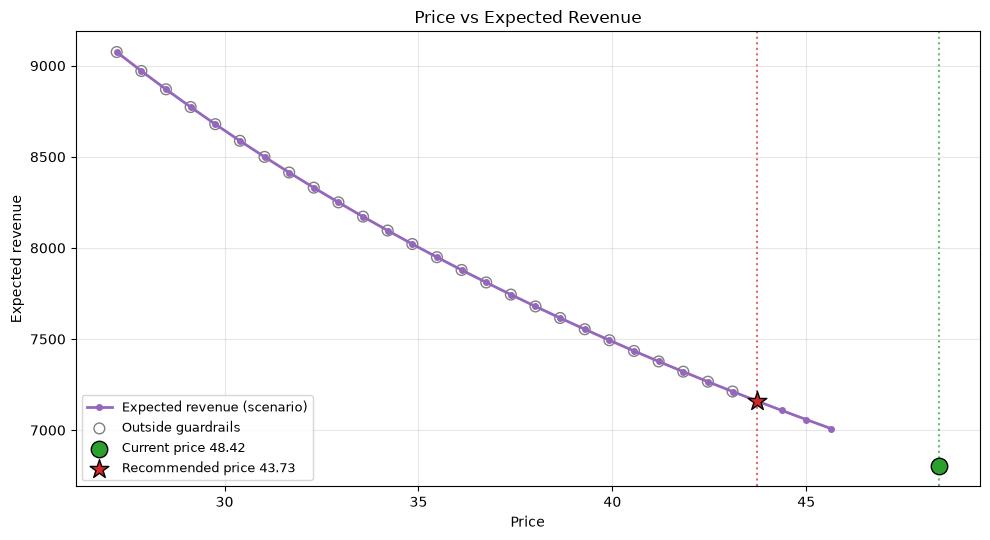

Optimization basis : Revenue-maximizing price - not profit-maximizing price
Current    expected revenue : 6,804.38
Recommended expected revenue: 7,159.60  (+5.22%)
Reminder: no unit cost is available, so no profit curve exists - this is a revenue curve.


In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(scenarios["Price"], scenarios[OBJECTIVE], color="tab:purple", lw=2, marker="o", ms=4,
        label=f"Expected {OBJECTIVE.lower()} (scenario)")

rejected = scenarios[~scenarios["Feasible"]]
if len(rejected):
    ax.scatter(rejected["Price"], rejected[OBJECTIVE], s=60, facecolors="none",
               edgecolors="gray", label="Outside guardrails")

ax.axvline(CURRENT_PRICE, color="tab:green", ls=":", alpha=0.7)
ax.scatter([CURRENT_PRICE], [CURRENT_OBJECTIVE], s=140, color="tab:green", zorder=5,
           edgecolor="black", label=f"Current price {CURRENT_PRICE:,.2f}")

if abs(RECOMMENDED_PRICE - CURRENT_PRICE) > 1e-9:
    ax.axvline(RECOMMENDED_PRICE, color="tab:red", ls=":", alpha=0.7)
ax.scatter([RECOMMENDED_PRICE], [RECOMMENDED_OBJECTIVE], s=200, marker="*", color="tab:red", zorder=6,
           edgecolor="black", label=f"Recommended price {RECOMMENDED_PRICE:,.2f}")

ax.set_xlabel("Price")
ax.set_ylabel(f"Expected {OBJECTIVE.lower()}")
ax.set_title(f"Price vs Expected {OBJECTIVE}")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Optimization basis : {OPTIMIZATION_BASIS_LABEL}")
print(f"Current    {OBJECTIVE_LABEL:<17}: {CURRENT_OBJECTIVE:,.2f}")
print(f"Recommended {OBJECTIVE_LABEL:<16}: {RECOMMENDED_OBJECTIVE:,.2f}  "
      f"({IMPROVEMENT_PCT:+.2f}%)" if np.isfinite(IMPROVEMENT_PCT)
      else f"Recommended {OBJECTIVE_LABEL}: {RECOMMENDED_OBJECTIVE:,.2f}")
if UNIT_COST is None:
    print("Reminder: no unit cost is available, so no profit curve exists - this is a revenue curve.")


## 17. Elasticity Sensitivity Analysis

A single elasticity assumption can look arbitrary, so the optimization is re-run across the grid
`[-0.5, -1.0, -1.5, -2.0, -2.5, -3.0]` using the identical scenario grid and guardrails.

| Elasticity | Optimal Price | Expected Demand | Expected Revenue | Expected Profit |
|------------|---------------|-----------------|------------------|-----------------|

This table is the credibility test of the recommendation: if the optimal price moves a lot across
plausible elasticities, the recommendation is **assumption-driven** and must be validated experimentally;
if it is stable, the recommendation is robust to the assumption. Under a constant-elasticity model the
optimum often sits at a guardrail boundary, which is why the guardrails matter as much as the estimate.

In [17]:
sensitivity_rows = []
for grid_elasticity in ELASTICITY_GRID:
    sim = simulate(SCENARIO_PRICES, grid_elasticity, BASELINE_DEMAND, CURRENT_PRICE,
                   CURRENT_DISCOUNT_PCT, UNIT_COST)
    sim, _ = apply_guardrails(sim, CURRENT_PRICE, UNIT_COST, GUARDRAILS)
    feasible_sim = sim[sim["Feasible"]]
    row = {"Elasticity": float(grid_elasticity)}
    if feasible_sim.empty:
        row.update({"Optimal Price": np.nan, "Expected Demand": np.nan,
                    "Expected Revenue": np.nan})
        if UNIT_COST is not None:
            row["Expected Profit"] = np.nan
        sensitivity_rows.append(row)
        continue
    best = feasible_sim.loc[int(feasible_sim[OBJECTIVE].idxmax())]
    row.update({
        "Optimal Price": float(best["Price"]),
        "Expected Demand": float(best["Adjusted_Demand"]),
        "Expected Revenue": float(best["Revenue"]),
    })
    if UNIT_COST is not None:
        row["Expected Profit"] = float(best["Profit"])
    sensitivity_rows.append(row)

sensitivity_table = pd.DataFrame(sensitivity_rows)

print("=" * 78)
print("ELASTICITY SENSITIVITY  (scenario grid + guardrails identical for every row)")
print("=" * 78)
display(sensitivity_table)

usable = sensitivity_table.dropna(subset=["Optimal Price"])
if len(usable):
    above = int((usable["Optimal Price"] > CURRENT_PRICE + 1e-9).sum())
    below = int((usable["Optimal Price"] < CURRENT_PRICE - 1e-9).sum())
    at_current = int(len(usable) - above - below)
    print(f"Current price                : {CURRENT_PRICE:,.2f}")
    print(f"Optimal price across grid    : {usable['Optimal Price'].min():,.2f} - "
          f"{usable['Optimal Price'].max():,.2f}")
    print(f"Grid points recommending     : above current = {above}, below current = {below}, "
          f"equal to current = {at_current}")
    print(f"Elasticity actually used     : {ELASTICITY_USED:+.3f} ({ELASTICITY_ORIGIN}) -> optimal "
          f"{RECOMMENDED_PRICE:,.2f}")
    if above and below:
        print("INTERPRETATION: the recommended direction changes with the elasticity assumption, so the "
              "recommendation is assumption-sensitive and must be validated with a controlled "
              "experiment (A/B test) before any price change.")
    else:
        print("INTERPRETATION: the recommended direction is stable across the tested elasticity grid, "
              "but the size of the effect still depends on the assumption.")
else:
    print("No feasible scenario available for any elasticity in the grid.")


ELASTICITY SENSITIVITY  (scenario grid + guardrails identical for every row)


,Elasticity,Optimal Price,Expected Demand,Expected Revenue
0,-0.5,45.640000,144.744848,6606.154844
1,-1.0,43.734483,155.583784,6804.376308
2,-1.5,43.734483,163.706048,7159.599335
3,-2.0,43.734483,172.252336,7533.366809
4,-2.5,43.734483,181.244783,7926.646845
5,-3.0,43.734483,190.706682,8340.458098


Current price                : 48.42
Optimal price across grid    : 43.73 - 45.64
Grid points recommending     : above current = 0, below current = 6, equal to current = 0
Elasticity actually used     : -1.500 (assumed) -> optimal 43.73
INTERPRETATION: the recommended direction is stable across the tested elasticity grid, but the size of the effect still depends on the assumption.


## 18. Cost Sensitivity

**This section always reports hypothetical costs as such - it never invents a unit cost for the
recommendation.**

* **When `Unit_Cost` exists:** the grid perturbs the *actual* business cost (+/-10%, +/-20%) to show how
  sensitive the optimum is to cost inputs.
* **When `Unit_Cost` is missing (this dataset):** instead of picking one convenient number, the engine
  shows what the profit-maximizing price *would* be under a range of **hypothetical** costs expressed as
  shares of the current price (30%, 40%, 50%, 60%, 70%), each clearly labelled:

> **"Hypothetical cost sensitivity - NOT actual company cost."**

The table answers the business question *"at roughly what cost level would raising the price start to
pay off?"* while leaving the real cost to be supplied by the company.

In [18]:
HYPOTHETICAL_COST_SHARES = [0.30, 0.40, 0.50, 0.60, 0.70]

print("=" * 78)
if UNIT_COST is not None:
    print("COST SENSITIVITY (around the actual business-provided unit cost)")
    print("=" * 78)
    print(f"Actual unit cost: {UNIT_COST:,.2f} (column '{UNIT_COST_COLUMN}')")
    cost_grid = [UNIT_COST * factor for factor in (0.8, 0.9, 1.0, 1.1, 1.2)]
    cost_labels = [f"{factor:.0%} of actual cost" for factor in (0.8, 0.9, 1.0, 1.1, 1.2)]
else:
    print("HYPOTHETICAL COST SENSITIVITY - NOT ACTUAL COMPANY COST")
    print("=" * 78)
    print("Unit cost is unavailable in the data, so every cost below is a hypothetical share of the "
          "current price. These numbers are for illustration only; true profit optimization requires "
          "a business-provided unit cost.")
    cost_grid = [CURRENT_PRICE * share for share in HYPOTHETICAL_COST_SHARES]
    cost_labels = [f"{share:.0%} of current price" for share in HYPOTHETICAL_COST_SHARES]

cost_rows = []
for label, cost in zip(cost_labels, cost_grid):
    sim = simulate(SCENARIO_PRICES, ELASTICITY_USED, BASELINE_DEMAND, CURRENT_PRICE,
                   CURRENT_DISCOUNT_PCT, cost)
    sim, _ = apply_guardrails(sim, CURRENT_PRICE, cost, GUARDRAILS)
    feasible_sim = sim[sim["Feasible"]]
    profit_at_current = (CURRENT_EFFECTIVE_PRICE - cost) * BASELINE_DEMAND
    if feasible_sim.empty:
        cost_rows.append({
            "Cost Basis": label, "Assumed Unit Cost": cost, "Recommended Price": np.nan,
            "Expected Demand": np.nan, "Expected Revenue": np.nan, "Expected Profit": np.nan,
            "Profitable at current price": bool(profit_at_current > 0),
        })
        continue
    best = feasible_sim.loc[int(feasible_sim["Profit"].idxmax())]
    cost_rows.append({
        "Cost Basis": label,
        "Assumed Unit Cost": float(cost),
        "Recommended Price": float(best["Price"]),
        "Expected Demand": float(best["Adjusted_Demand"]),
        "Expected Revenue": float(best["Revenue"]),
        "Expected Profit": float(best["Profit"]),
        "Profitable at current price": bool(profit_at_current > 0),
    })

cost_table = pd.DataFrame(cost_rows)
display(cost_table)

if UNIT_COST is None:
    print("Reminder: 'Assumed Unit Cost' values above are HYPOTHETICAL and are NOT the company's cost.")
    print("They are never used for the headline recommendation, which stays revenue-based.")
else:
    print("Reminder: costs are perturbations of the actual unit cost; the headline recommendation "
          "uses the actual cost row.")
print(f"Recommendation under the actual configuration ({OPTIMIZATION_BASIS} basis): "
      f"{RECOMMENDED_PRICE:,.2f} -> {ACTION}")


HYPOTHETICAL COST SENSITIVITY - NOT ACTUAL COMPANY COST
Unit cost is unavailable in the data, so every cost below is a hypothetical share of the current price. These numbers are for illustration only; true profit optimization requires a business-provided unit cost.


,Cost Basis,Assumed Unit Cost,Recommended Price,Expected Demand,Expected Revenue,Expected Profit,Profitable at current price
0,30% of current price,14.526,43.734483,163.706048,7159.599335,4781.605281,True
1,40% of current price,19.368,45.640000,153.561471,7008.545520,4034.366957,True
2,50% of current price,24.210,45.640000,153.561471,7008.545520,3290.822316,True
3,60% of current price,29.052,45.640000,153.561471,7008.545520,2547.277675,True
4,70% of current price,33.894,45.640000,153.561471,7008.545520,1803.733034,True


Reminder: 'Assumed Unit Cost' values above are HYPOTHETICAL and are NOT the company's cost.
They are never used for the headline recommendation, which stays revenue-based.
Recommendation under the actual configuration (revenue basis): 43.73 -> LOWER


## 19. Business Guardrails

Guardrails are the constraints that keep a mathematically optimal price inside what the business is
willing to do. All are configurable in section 2:

| Guardrail | Setting | Meaning |
|-----------|---------|---------|
| `MIN_PRICE` / `MAX_PRICE` | None -> historical scenario bounds | never price outside the observed range |
| `MAX_PRICE_CHANGE_PCT` | 10% | no recommendation moves the price further than this in one step |
| `MIN_PROFIT_MARGIN` | 5% | (profit mode) a scenario must keep a minimum margin |
| `MIN_EXPECTED_DEMAND` | None | optional absolute demand floor |

The cell below reports how many scenarios each guardrail blocked, whether the unconstrained optimum was
rejected, and **re-validates the final recommendation** against every rule. If the recommendation were to
violate a guardrail, the best feasible scenario would be selected instead.

In [19]:
print("=" * 78)
print("GUARDRAIL CONFIGURATION")
print("=" * 78)
print(f"{'Minimum price':<34}: " +
      (f"{GUARDRAIL_MIN_PRICE:,.2f}" if GUARDRAILS["min_price"] is not None
       else f"not set -> scenario lower bound {SCENARIO_MIN:,.2f}"))
print(f"{'Maximum price':<34}: " +
      (f"{GUARDRAIL_MAX_PRICE:,.2f}" if GUARDRAILS["max_price"] is not None
       else f"not set -> scenario upper bound {SCENARIO_MAX:,.2f}"))
print(f"{'Maximum price change':<34}: +/-{MAX_PRICE_CHANGE_PCT:.1f}% of the current price")
print(f"{'Minimum profit margin':<34}: {MIN_PROFIT_MARGIN:.0%}" +
      ("" if UNIT_COST is not None else " (profit mode only - not active)"))
print(f"{'Minimum expected demand':<34}: " +
      (f"{MIN_EXPECTED_DEMAND:,.1f} units" if MIN_EXPECTED_DEMAND is not None else "not configured"))
print(f"{'Minimum improvement':<34}: {MIN_IMPROVEMENT_PCT:.1f}% before changing the price")

print("-" * 78)
print("SCENARIOS BLOCKED BY GUARDRAIL")
for rule, count in GUARDRAIL_BLOCKS.items():
    print(f"  {rule:<26}: {count} of {len(scenarios)}")
print(f"  {'feasible':<26}: {int(scenarios['Feasible'].sum())} of {len(scenarios)}")

print("-" * 78)
print("UNCONSTRAINED OPTIMUM vs GUARDRAILS")
unconstrained_change = float(UNCONSTRAINED_BEST["Price_Change_Pct"])
print(f"  unconstrained optimum : {UNCONSTRAINED_BEST['Price']:,.2f} "
      f"({unconstrained_change:+.2f}% vs current) - "
      f"{'FEASIBLE' if bool(UNCONSTRAINED_BEST['Feasible']) else 'REJECTED: ' + str(UNCONSTRAINED_BEST['Guardrail_Violation'])}")
print(f"  recommendation        : {RECOMMENDED_PRICE:,.2f} "
      f"({(RECOMMENDED_PRICE / CURRENT_PRICE - 1) * 100:+.2f}% vs current)")
if GUARDRAIL_BLOCKED:
    print("  outcome               : no feasible scenario - current price held")
elif abs(UNCONSTRAINED_BEST["Price"] - RECOMMENDED_PRICE) > 1e-9:
    print("  outcome               : guardrail-constrained scenario selected instead "
          "of the unconstrained optimum")
else:
    print("  outcome               : unconstrained optimum already respects every guardrail")

# --- final re-validation of the recommendation --------------------------------
recommended_change_pct = abs(RECOMMENDED_PRICE - CURRENT_PRICE) / CURRENT_PRICE * 100.0
if UNIT_COST is not None and RECOMMENDED_EFFECTIVE_PRICE > 0:
    recommended_margin = (RECOMMENDED_EFFECTIVE_PRICE - UNIT_COST) / RECOMMENDED_EFFECTIVE_PRICE
else:
    recommended_margin = np.nan

GUARDRAIL_VALIDATION = {
    "within_price_bounds": bool(GUARDRAIL_MIN_PRICE - 1e-9 <= RECOMMENDED_PRICE
                                <= GUARDRAIL_MAX_PRICE + 1e-9),
    "price_change_within_limit": bool(recommended_change_pct <= MAX_PRICE_CHANGE_PCT + 1e-9),
    "margin_ok": bool(UNIT_COST is None or (np.isfinite(recommended_margin)
                                            and recommended_margin >= MIN_PROFIT_MARGIN - 1e-9)),
    "demand_ok": bool(MIN_EXPECTED_DEMAND is None or RECOMMENDED_DEMAND >= MIN_EXPECTED_DEMAND),
}

if not all(GUARDRAIL_VALIDATION.values()):
    print("WARNING: the recommendation violates a guardrail - selecting the best feasible scenario.")
    if not feasible_rows.empty:
        fallback = feasible_rows.loc[int(feasible_rows[OBJECTIVE].idxmax())]
        RECOMMENDED_PRICE = float(fallback["Price"])
        RECOMMENDED_EFFECTIVE_PRICE = float(fallback["Effective_Price"])
        RECOMMENDED_DEMAND = float(fallback["Adjusted_Demand"])
        RECOMMENDED_REVENUE = float(fallback["Revenue"])
        RECOMMENDED_PROFIT = float(fallback["Profit"]) if "Profit" in fallback else None
        RECOMMENDED_OBJECTIVE = float(fallback[OBJECTIVE])
    else:
        RECOMMENDED_PRICE, RECOMMENDED_EFFECTIVE_PRICE = CURRENT_PRICE, CURRENT_EFFECTIVE_PRICE
        RECOMMENDED_DEMAND, RECOMMENDED_REVENUE = BASELINE_DEMAND, CURRENT_REVENUE
        RECOMMENDED_PROFIT, RECOMMENDED_OBJECTIVE = CURRENT_PROFIT, CURRENT_OBJECTIVE
        GUARDRAIL_BLOCKED = True
    IMPROVEMENT_ABS = RECOMMENDED_OBJECTIVE - CURRENT_OBJECTIVE
    IMPROVEMENT_PCT = pct_change(RECOMMENDED_OBJECTIVE, CURRENT_OBJECTIVE)
    DECISION = decide_pricing_action(
        data_quality=PRICE_QUALITY, optimization_basis=OPTIMIZATION_BASIS,
        current_price=CURRENT_PRICE, recommended_price=RECOMMENDED_PRICE,
        current_objective=CURRENT_OBJECTIVE, max_feasible_objective=MAX_FEASIBLE_OBJECTIVE,
        improvement_abs=IMPROVEMENT_ABS, improvement_pct=IMPROVEMENT_PCT,
        guardrail_blocked=GUARDRAIL_BLOCKED)
    ACTION, ACTION_REASON = DECISION["action"], DECISION["reason"]
    OPTIMIZATION_BASIS_LABEL = DECISION["basis_label"]
    recommended_change_pct = abs(RECOMMENDED_PRICE - CURRENT_PRICE) / CURRENT_PRICE * 100.0
    if UNIT_COST is not None and RECOMMENDED_EFFECTIVE_PRICE > 0:
        recommended_margin = (RECOMMENDED_EFFECTIVE_PRICE - UNIT_COST) / RECOMMENDED_EFFECTIVE_PRICE
    else:
        recommended_margin = np.nan
    GUARDRAIL_VALIDATION = {
        "within_price_bounds": bool(GUARDRAIL_MIN_PRICE - 1e-9 <= RECOMMENDED_PRICE
                                    <= GUARDRAIL_MAX_PRICE + 1e-9),
        "price_change_within_limit": bool(recommended_change_pct <= MAX_PRICE_CHANGE_PCT + 1e-9),
        "margin_ok": bool(UNIT_COST is None or (np.isfinite(recommended_margin)
                                                and recommended_margin >= MIN_PROFIT_MARGIN - 1e-9)),
        "demand_ok": bool(MIN_EXPECTED_DEMAND is None or RECOMMENDED_DEMAND >= MIN_EXPECTED_DEMAND),
    }
    print("Decision refreshed after the guardrail fallback.")

print("-" * 78)
print("FINAL GUARDRAIL VALIDATION OF THE RECOMMENDATION")
for rule, passed in GUARDRAIL_VALIDATION.items():
    print(f"  {rule:<28}: {'PASS' if passed else 'FAIL'}")
GUARDRAILS_PASSED = bool(all(GUARDRAIL_VALIDATION.values()))
print("Guardrails:", "Passed" if GUARDRAILS_PASSED else "Failed")


GUARDRAIL CONFIGURATION
Minimum price                     : not set -> scenario lower bound 27.22
Maximum price                     : not set -> scenario upper bound 45.64
Maximum price change              : +/-10.0% of the current price
Minimum profit margin             : 5% (profit mode only - not active)
Minimum expected demand           : not configured
Minimum improvement               : 0.0% before changing the price
------------------------------------------------------------------------------
SCENARIOS BLOCKED BY GUARDRAIL
  max_price_change_pct      : 26 of 30
  price_bounds              : 0 of 30
  min_profit_margin         : 0 of 30
  min_expected_demand       : 0 of 30
  feasible                  : 4 of 30
------------------------------------------------------------------------------
UNCONSTRAINED OPTIMUM vs GUARDRAILS
  unconstrained optimum : 27.22 (-43.78% vs current) - REJECTED: price change beyond +/-10.0%
  recommendation        : 43.73 (-9.68% vs current)
  outcome  

## 20. Final Recommendation

The consolidated business output: what to do, why, under which assumptions, and with what data quality.
Negative-profit scenarios are handled explicitly - when no price in the tested range is expected to be
profitable, the action is `NO_GO` rather than the "mathematical maximum" of a set of losses.

In [20]:
PRODUCT_LABEL = ", ".join(f"{key}={SELECTED_SERIES[key]}" for key in SERIES_KEYS)


def fmt_money(value):
    return f"{value:,.2f}" if value is not None and np.isfinite(value) else "n/a"


line = "=" * 78
print(line)
print("PRICING RECOMMENDATION")
print("-" * 78)
print(f"Product                     : {PRODUCT_LABEL}")
print(f"Current Price               : {CURRENT_PRICE:,.2f}")
print(f"Recommended Price           : {RECOMMENDED_PRICE:,.2f} "
      f"({(RECOMMENDED_PRICE / CURRENT_PRICE - 1) * 100:+.2f}%)")
print(f"Action                      : {ACTION}")
if ACTION == "NO_GO":
    print("                              No price within the tested historical range is expected to "
          "generate positive profit under the current assumptions.")
elif ACTION == "INSUFFICIENT_DATA":
    print("                              Historical price variation is insufficient for reliable "
          "price-response estimation. Treat the output as scenario analysis only.")
print("-" * 78)
print(f"Current Expected Demand     : {BASELINE_DEMAND:,.2f} units")
print(f"Recommended Expected Demand : {RECOMMENDED_DEMAND:,.2f} units")
print("-" * 78)
print(f"Current Expected Revenue    : {fmt_money(CURRENT_REVENUE)}")
print(f"Recommended Expected Revenue: {fmt_money(RECOMMENDED_REVENUE)}")
print(f"Revenue Change              : {fmt_money(RECOMMENDED_REVENUE - CURRENT_REVENUE)}"
      f"  ({(pct_change(RECOMMENDED_REVENUE, CURRENT_REVENUE)):+.2f}%)"
      if np.isfinite(pct_change(RECOMMENDED_REVENUE, CURRENT_REVENUE))
      else "Revenue Change              : n/a")
print("-" * 78)
if UNIT_COST is not None:
    print(f"Current Expected Profit     : {fmt_money(CURRENT_PROFIT)}")
    print(f"Recommended Expected Profit : {fmt_money(RECOMMENDED_PROFIT)}")
    profit_change = RECOMMENDED_PROFIT - CURRENT_PROFIT
    print(f"Profit Change               : {fmt_money(profit_change)}"
          + (f"  ({pct_change(RECOMMENDED_PROFIT, CURRENT_PROFIT):+.2f}%)"
             if np.isfinite(pct_change(RECOMMENDED_PROFIT, CURRENT_PROFIT)) else ""))
    print(f"Expected Margin             : "
          f"{(RECOMMENDED_EFFECTIVE_PRICE - UNIT_COST) / RECOMMENDED_EFFECTIVE_PRICE:.2%}"
          if RECOMMENDED_EFFECTIVE_PRICE > 0 else "Expected Margin             : n/a")
else:
    print("Current Expected Profit     : n/a - no unit cost provided by the business")
    print("Recommended Expected Profit : n/a - no unit cost provided by the business")
    print("Profit Change               : n/a - profit optimization requires a business-provided "
          "unit cost")
print("-" * 78)
print(f"Optimization basis          : {OPTIMIZATION_BASIS_LABEL}")
print(f"Elasticity used             : {ELASTICITY_USED:+.4f}")
print(f"Elasticity source           : {ELASTICITY_SOURCE}")
print(f"Data quality                : {PRICE_QUALITY}")
print(f"Guardrails                  : {'Passed' if GUARDRAILS_PASSED else 'Failed'} "
      f"(max change +/-{MAX_PRICE_CHANGE_PCT:.1f}%)")
print("-" * 78)
print(f"Decision                    : {ACTION}")
print(f"Reason                      : {ACTION_REASON}")
print(line)
print("This is a decision-support recommendation. Validate with a controlled experiment (A/B test) "
      "or business review before changing any price.")


PRICING RECOMMENDATION
------------------------------------------------------------------------------
Product                     : Product_ID=P0006, Store_ID=S003
Current Price               : 48.42
Recommended Price           : 43.73 (-9.68%)
Action                      : LOWER
------------------------------------------------------------------------------
Current Expected Demand     : 140.53 units
Recommended Expected Demand : 163.71 units
------------------------------------------------------------------------------
Current Expected Revenue    : 6,804.38
Recommended Expected Revenue: 7,159.60
Revenue Change              : 355.22  (+5.22%)
------------------------------------------------------------------------------
Current Expected Profit     : n/a - no unit cost provided by the business
Recommended Expected Profit : n/a - no unit cost provided by the business
Profit Change               : n/a - profit optimization requires a business-provided unit cost
----------------------------

## 21. Limitations

1. **Forecasting accuracy does not imply causal price effects.** The demand model's test metrics
   (MAE / R2) describe how well it predicts demand under historical conditions. They say nothing about
   what would happen to demand if the price were changed.

2. **Elasticity estimated from observational data can be biased.** The log-log coefficient is an
   association in whatever history the company happens to have. Prices were set for business reasons
   (markdowns, clearance, demand response, competitor moves), so the estimate is not identified as a
   causal parameter - and in this dataset it was flagged and replaced by the configured assumption.

3. **Promotions, seasonality, inventory, competition, and product mix confound price-demand
   relationships.** A cheap week that coincides with a promotion or a stock clearance will make price
   and demand move together (or apart) for reasons that have nothing to do with price sensitivity.

4. **The historical price range limits the optimization search space.** Scenarios are restricted to the
   5th-95th percentile of historical prices by design; the engine never proposes a price the company
   has not effectively tested before.

5. **Unit cost must come from the business for true profit optimization.** Without it the engine
   optimizes revenue and reports hypothetical cost scenarios only - it never fabricates a cost.

6. **New products with little or no pricing history need a fallback strategy.** With insufficient price
   variation the engine returns `INSUFFICIENT_DATA` and behaves as a scenario-analysis tool; a real
   launch strategy (competitor-based pricing, hedonic benchmarking, or a planned price test) must come
   from the business.

7. **Recommendations must be validated before deployment** through controlled experiments / A/B tests
   or structured business review. The sensitivity tables show how much of the answer depends on
   assumptions, and guardrails should stay in place for any live rollout.

## 22. Final Sanity Checks

Automated verification that the notebook's output is internally consistent and honest:

* no negative scenario prices, no negative predicted demand, no NaN in key outputs,
* current price exists and the scenario price range is valid,
* the recommended price lies inside the allowed range **and** respects every guardrail,
* the elasticity is explicitly identified as `estimated` or `assumed`,
* no `Unit_Cost` was invented (a cost value only exists if the data or the business supplied it),
* no causal claim appears in the recommendation text.

In [21]:
CAUSAL_CLAIM_PATTERNS = [
    r"\bwill (cause|increase|decrease|raise|lower|boost|reduce|grow)\b",
    r"\bcauses?\b",
    r"\bdrives?\b",
    r"\bguarantees?\b",
    r"\bproves?\b",
    r"\bis proven\b",
    r"\bcertain(ly)? to\b",
    r"\bdemand will\b",
    r"\bprices? will\b",
]

NARRATIVE_TEXTS = [
    ACTION_REASON,
    OPTIMIZATION_BASIS_LABEL,
    ELASTICITY_SOURCE,
    DECISION.get("reason", ""),
]
causal_hits = []
for text in NARRATIVE_TEXTS:
    for pattern in CAUSAL_CLAIM_PATTERNS:
        if re.search(pattern, str(text), flags=re.IGNORECASE):
            causal_hits.append((pattern, str(text)))

checks = []


def check(name, passed, detail=""):
    checks.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": str(detail)})


price_values = scenarios["Price"].to_numpy(dtype=float)
check("No negative scenario prices", bool(np.all(price_values > 0)),
      f"min={price_values.min():.4f}")
check("No negative predicted demand",
      bool((scenarios["Adjusted_Demand"] >= 0).all()) and bool(BASELINE_DEMAND >= 0),
      f"min adjusted={scenarios['Adjusted_Demand'].min():.4f}, baseline={BASELINE_DEMAND:.4f}")

key_columns = ["Price", "Price_Ratio", "Effective_Price", "Adjusted_Demand", "Revenue"]
if UNIT_COST is not None:
    key_columns.append("Profit")
nan_count = int(scenarios[key_columns].isna().sum().sum())
check("No NaN in key outputs", nan_count == 0, f"{nan_count} NaN values in {key_columns}")

check("Current price exists", bool(np.isfinite(CURRENT_PRICE) and CURRENT_PRICE > 0),
      f"{CURRENT_PRICE:.4f}")
range_valid = (np.isfinite(SCENARIO_MIN) and np.isfinite(SCENARIO_MAX)
               and 0 < SCENARIO_MIN <= SCENARIO_MAX
               and SCENARIO_MIN >= 0)
check("Scenario price range is valid", range_valid,
      f"{SCENARIO_MIN:.2f} - {SCENARIO_MAX:.2f} ({N_SCENARIOS} scenarios)")

allowed_low = min(SCENARIO_MIN, CURRENT_PRICE)
allowed_high = max(SCENARIO_MAX, CURRENT_PRICE)
check("Recommended price inside allowed range",
      bool(allowed_low - 1e-9 <= RECOMMENDED_PRICE <= allowed_high + 1e-9),
      f"{RECOMMENDED_PRICE:.2f} within [{allowed_low:.2f}, {allowed_high:.2f}]")

failed_guardrails = [rule for rule, passed in GUARDRAIL_VALIDATION.items() if not passed]
check("Recommended price respects guardrails", not failed_guardrails,
      "all rules pass" if not failed_guardrails else "violated: " + ", ".join(failed_guardrails))

elasticity_identified = (
    ELASTICITY_ORIGIN in {"estimated", "assumed"}
    and isinstance(ELASTICITY_SOURCE, str) and len(ELASTICITY_SOURCE) > 0
    and (ELASTICITY_ORIGIN == "estimated" and "estimate" in ELASTICITY_SOURCE.lower()
         or ELASTICITY_ORIGIN == "assumed" and "assumption" in ELASTICITY_SOURCE.lower())
    and ELASTICITY_MIN <= ELASTICITY_USED <= ELASTICITY_MAX
)
check("Elasticity explicitly identified as estimated or assumed", elasticity_identified,
      f"origin={ELASTICITY_ORIGIN}, value={ELASTICITY_USED:+.3f}")

cost_traced_to_source = (UNIT_COST is None and DEFAULT_UNIT_COST is None and UNIT_COST_COLUMN is None) \
    or (UNIT_COST is not None and (UNIT_COST_COLUMN is not None or DEFAULT_UNIT_COST is not None))
check("No fake Unit_Cost introduced", cost_traced_to_source,
      "UNIT_COST is None (no cost available)" if UNIT_COST is None
      else f"UNIT_COST={UNIT_COST:,.2f} traced to column '{UNIT_COST_COLUMN}'")

check("No causal claims in output", not causal_hits,
      "clean" if not causal_hits else "; ".join(f"{p} in '{t}'" for p, t in causal_hits))

check("Action is a valid business outcome", ACTION in {"KEEP", "RAISE", "LOWER", "NO_GO",
                                                       "INSUFFICIENT_DATA"}, ACTION)
check("Optimization basis is declared",
      OPTIMIZATION_BASIS in {"profit", "revenue"} and bool(OPTIMIZATION_BASIS_LABEL),
      OPTIMIZATION_BASIS_LABEL)

checks_table = pd.DataFrame(checks)
print("=" * 78)
print("PRICE OPTIMIZATION SANITY CHECKS")
print("=" * 78)
display(checks_table)

SANITY_CHECKS_PASSED = bool((checks_table["Result"] == "PASS").all())
if SANITY_CHECKS_PASSED:
    print("ALL PRICE OPTIMIZATION SANITY CHECKS PASSED")
else:
    print("SANITY CHECK FAILURES:")
    for row in checks_table[checks_table["Result"] == "FAIL"].itertuples():
        print(f"  FAIL: {row.Check} - {row.Detail}")


PRICE OPTIMIZATION SANITY CHECKS


,Check,Result,Detail
0,No negative scenario prices,PASS,min=27.2200
1,No negative predicted demand,PASS,"min adjusted=153.5615, baseline=140.5282"
2,No NaN in key outputs,PASS,"0 NaN values in ['Price', 'Price_Ratio', 'Effe..."
3,Current price exists,PASS,48.4200
4,Scenario price range is valid,PASS,27.22 - 45.64 (30 scenarios)
5,Recommended price inside allowed range,PASS,"43.73 within [27.22, 48.42]"
6,Recommended price respects guardrails,PASS,all rules pass
7,Elasticity explicitly identified as estimated ...,PASS,"origin=assumed, value=-1.500"
8,No fake Unit_Cost introduced,PASS,UNIT_COST is None (no cost available)
9,No causal claims in output,PASS,clean


ALL PRICE OPTIMIZATION SANITY CHECKS PASSED


## 23. Final Summary

Machine-readable summary of the whole run: product, prices, action, elasticity provenance, demand,
revenue, profit, data quality, guardrail and sanity status.

In [22]:
SUMMARY = {
    "Product": PRODUCT_LABEL,
    "Current Price": round(float(CURRENT_PRICE), 4),
    "Recommended Price": round(float(RECOMMENDED_PRICE), 4),
    "Action": ACTION,
    "Elasticity": round(float(ELASTICITY_USED), 4),
    "Elasticity Source": ELASTICITY_SOURCE,
    "Elasticity Origin": ELASTICITY_ORIGIN,
    "Baseline Demand": round(float(BASELINE_DEMAND), 4),
    "Recommended Demand": round(float(RECOMMENDED_DEMAND), 4),
    "Baseline Revenue": round(float(CURRENT_REVENUE), 4),
    "Recommended Revenue": round(float(RECOMMENDED_REVENUE), 4),
    "Baseline Profit": (round(float(CURRENT_PROFIT), 4) if CURRENT_PROFIT is not None else None),
    "Recommended Profit": (round(float(RECOMMENDED_PROFIT), 4)
                           if RECOMMENDED_PROFIT is not None else None),
    "Data Quality": PRICE_QUALITY,
    "Optimization Basis": OPTIMIZATION_BASIS_LABEL,
    "Unit Cost Available": UNIT_COST is not None,
    "Guardrails": "Passed" if GUARDRAILS_PASSED else "Failed",
    "Sanity Checks": "Passed" if SANITY_CHECKS_PASSED else "Failed",
    "Decision Reason": ACTION_REASON,
}

print("=" * 62)
print("PRICE OPTIMIZATION SUMMARY")
print("=" * 62)
print(f"Product              : {SUMMARY['Product']}")
print(f"Current Price        : {SUMMARY['Current Price']:,.2f}")
print(f"Recommended Price    : {SUMMARY['Recommended Price']:,.2f}")
print(f"Action               : {SUMMARY['Action']}")
print()
print(f"Elasticity           : {SUMMARY['Elasticity']:+.4f}")
print(f"Elasticity Source    : {SUMMARY['Elasticity Source']}")
print()
print(f"Baseline Demand      : {SUMMARY['Baseline Demand']:,.2f}")
print(f"Recommended Demand   : {SUMMARY['Recommended Demand']:,.2f}")
print()
print(f"Baseline Revenue     : {SUMMARY['Baseline Revenue']:,.2f}")
print(f"Recommended Revenue  : {SUMMARY['Recommended Revenue']:,.2f}")
print()
print("Baseline Profit      : " +
      (f"{SUMMARY['Baseline Profit']:,.2f}" if SUMMARY["Baseline Profit"] is not None
       else "n/a (revenue optimization - no business unit cost)"))
print("Recommended Profit   : " +
      (f"{SUMMARY['Recommended Profit']:,.2f}" if SUMMARY["Recommended Profit"] is not None
       else "n/a (revenue optimization - no business unit cost)"))
print()
print(f"Data Quality         : {SUMMARY['Data Quality']}")
print(f"Optimization Basis   : {SUMMARY['Optimization Basis']}")
print()
print(f"Guardrails           : {SUMMARY['Guardrails']}")
print(f"Sanity Checks        : {SUMMARY['Sanity Checks']}")
print("=" * 62)
print("machine-readable:")
print(json.dumps(SUMMARY, indent=2, default=str))


PRICE OPTIMIZATION SUMMARY
Product              : Product_ID=P0006, Store_ID=S003
Current Price        : 48.42
Recommended Price    : 43.73
Action               : LOWER

Elasticity           : -1.5000
Elasticity Source    : Scenario elasticity assumption (DEFAULT_ELASTICITY = -1.5) - not causally estimated

Baseline Demand      : 140.53
Recommended Demand   : 163.71

Baseline Revenue     : 6,804.38
Recommended Revenue  : 7,159.60

Baseline Profit      : n/a (revenue optimization - no business unit cost)
Recommended Profit   : n/a (revenue optimization - no business unit cost)

Data Quality         : GOOD
Optimization Basis   : Revenue-maximizing price - not profit-maximizing price

Guardrails           : Passed
Sanity Checks        : Passed
machine-readable:
{
  "Product": "Product_ID=P0006, Store_ID=S003",
  "Current Price": 48.42,
  "Recommended Price": 43.7345,
  "Action": "LOWER",
  "Elasticity": -1.5,
  "Elasticity Source": "Scenario elasticity assumption (DEFAULT_ELASTICITY = -1.